# Fase 2 — Entendimento dos Dados

**Projeto:** Previsão de demanda e política de estoque — Rede Bandeirante (CRISP-DM)
**Base principal:** `data/raw/demanda.csv` (grão **produto × dia**).
**Base auxiliar:** `data/raw/demanda_por_loja.csv` (usada apenas em checagens pontuais).

## Objetivo desta fase
Entender o que os dados realmente medem, o que eles deixam de medir e quais registros não deveriam entrar
no escopo de um modelo de previsão. É a fase que separa "venda observada" de "demanda real" e que sustenta
as decisões de modelagem.

## Achados e decisões registrados
- **Grão de trabalho = produto × dia** (base `demanda.csv`). A base `demanda_por_loja.csv` foi usada para
  checagens e depois **saiu do escopo** do projeto.
- **Produto foco do estudo detalhado:** **P0131**.
- **`unidades` registra VENDA, não DEMANDA** — em dias de ruptura a venda é truncada (o que se perdeu não
  aparece na coluna). Consequência: um modelo treinado nela aprende o teto da venda, não a demanda latente.
- **`estoque_total` é saldo de FIM de dia (após a venda)**, não estoque de início de dia.
- **Comparação loja vs rede:** a série agregada da rede é muito mais regular que a série de uma loja
  individual — motivo pelo qual a decisão de compra é feita no CD.
- **Sazonalidade semanal confirmada (período 7).** STL robusta no P0131: força da **tendência ≈ 0,86** e
  força da **sazonalidade ≈ 0,41** (fórmula de força de Hyndman).
- **Promoção (`pct_lojas_promo`)** multiplica a venda média do P0131 por ≈ **1,48×**, e é conhecida com
  **6 a 8 semanas de antecedência** → entra como **variável exógena futura conhecida**.
- **Triagem dos 30 produtos:** itens com razão (média recente 90d) / (média anterior) **< 0,6** são
  candidatos a descontinuação (P0438, P0051, P0079) — a remoção é decidida e aplicada na **Fase 3**.
- **SEED = 42** em toda aleatoriedade do projeto.


In [1]:
%matplotlib inline
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns
from statsmodels.tsa.seasonal import STL

# Os caminhos abaixo são relativos à RAIZ do projeto. Como o kernel pode ser
# iniciado na pasta do notebook (ex.: nbconvert), normalizamos o diretório de
# trabalho para a raiz do projeto, onde fica data/raw/demanda.csv.
for _cand in (".", "..", "../..", "../../.."):
    if os.path.exists(os.path.join(_cand, "data", "raw", "demanda.csv")):
        os.chdir(_cand)
        break
print("Diretório de trabalho:", os.getcwd())

SEED = 42
np.random.seed(SEED)

CAMINHO_REDE = "data/raw/demanda.csv"
CAMINHO_LOJA = "data/raw/demanda_por_loja.csv"
PASTA_FIGURAS = "reports/figures"
os.makedirs(PASTA_FIGURAS, exist_ok=True)


Diretório de trabalho: C:\Users\flavi\Documents\GitHub\Supply-Chain-Forecasting


## 2.1 Características gerais, tipos, dicionário, nulos e continuidade (itens 1 a 5)

Carregamos a base agregada da rede e respondemos: quantas linhas, quantos produtos, qual período, quais
tipos de dado, a interpretação de cada coluna, a presença de nulos e a continuidade temporal por produto.


In [2]:
df = pd.read_csv(CAMINHO_REDE, sep=",", parse_dates=["data"], dayfirst=False)

print("=" * 60)
print("ITEM 1: Características gerais da base")
print("=" * 60)
n_linhas = df.shape[0]
n_produtos = df["produto"].nunique()
data_min = df["data"].min()
data_max = df["data"].max()
n_dias = df["data"].nunique()
print(f"Numero de linhas: {n_linhas:,}")
print(f"Numero de produtos distintos: {n_produtos}")
print(f"Data minima: {data_min.strftime('%d/%m/%Y')}")
print(f"Data maxima: {data_max.strftime('%d/%m/%Y')}")
print(f"Quantidade de dias distintos: {n_dias}")
dias_total = (data_max - data_min).days + 1
print(f"Total de dias no periodo (incluindo extremos): {dias_total}")
print()

print("=" * 60)
print("ITEM 2: Primeiras linhas e tipos de dado")
print("=" * 60)
print("Tipos de dado das colunas:")
print(df.dtypes)
print()
print("Primeiras 10 linhas:")
print(df.head(10).to_string())
print()
print("Ultimas 5 linhas:")
print(df.tail(5).to_string())
print()


ITEM 1: Características gerais da base
Numero de linhas: 30,849
Numero de produtos distintos: 30
Data minima: 02/01/2017
Data maxima: 31/10/2019
Quantidade de dias distintos: 1033
Total de dias no periodo (incluindo extremos): 1033

ITEM 2: Primeiras linhas e tipos de dado
Tipos de dado das colunas:
produto                       str
data               datetime64[us]
unidades                  float64
preco_medio               float64
pct_lojas_promo           float64
estoque_total             float64
lojas_ativas                int64
dtype: object

Primeiras 10 linhas:
  produto       data  unidades  preco_medio  pct_lojas_promo  estoque_total  lojas_ativas
0   P0017 2017-01-02      89.0         1.49           0.0000         2023.0            75
1   P0017 2017-01-03      74.0         1.49           0.0000         2040.0            76
2   P0017 2017-01-04     114.0         1.49           0.0000         1993.0            77
3   P0017 2017-01-05     175.0         1.49           0.9221     

In [3]:
print("=" * 60)
print("ITEM 3: Dicionario de dados (interpretacao)")
print("=" * 60)
print("produto        | texto      | Codigo interno do SKU do produto. Chave primaria no nivel de produto.")
print("data           | datetime64 | Data de referencia da venda (dia). Chave primaria no nivel temporal.")
print("unidades       | float64    | Unidades vendidas no dia, somadas em todas as lojas da rede. COLUNA ALVO. Unidade: unidades fisicas.")
print("preco_medio    | float64    | Preco praticado no dia, media ponderada das lojas da rede. Unidade: R$ por unidade.")
print("pct_lojas_promo| float64    | Fracao das lojas ativas com o item em promocao no dia. Unidade: 0 a 1 (0% a 100%).")
print("estoque_total  | float64    | Saldo de estoque do item somado nas lojas da rede ao final do dia. Unidade: unidades fisicas.")
print("lojas_ativas   | int64      | Numero de lojas que comercializaram o item no dia (lojas com venda > 0). Unidade: lojas.")
print()

print("=" * 60)
print("ITEM 4: Valores nulos por coluna")
print("=" * 60)
nulos_qtd = df.isnull().sum()
nulos_pct = (nulos_qtd / n_linhas) * 100
df_nulos = pd.DataFrame({
    "quantidade_nulos": nulos_qtd,
    "percentual_nulos_pct": nulos_pct.round(4)
})
df_nulos = df_nulos[df_nulos["quantidade_nulos"] > 0].sort_values("quantidade_nulos", ascending=False)
if df_nulos.empty:
    print("NAO HA VALORES NULOS EM NENHUMA COLUNA.")
    print()
    print("Distribuicao dos nulos (todas zero):")
    print(pd.DataFrame({
        "quantidade_nulos": nulos_qtd,
        "percentual_nulos_pct": nulos_pct.round(4)
    }).to_string())
else:
    print(df_nulos.to_string())
print()


ITEM 3: Dicionario de dados (interpretacao)
produto        | texto      | Codigo interno do SKU do produto. Chave primaria no nivel de produto.
data           | datetime64 | Data de referencia da venda (dia). Chave primaria no nivel temporal.
unidades       | float64    | Unidades vendidas no dia, somadas em todas as lojas da rede. COLUNA ALVO. Unidade: unidades fisicas.
preco_medio    | float64    | Preco praticado no dia, media ponderada das lojas da rede. Unidade: R$ por unidade.
pct_lojas_promo| float64    | Fracao das lojas ativas com o item em promocao no dia. Unidade: 0 a 1 (0% a 100%).
estoque_total  | float64    | Saldo de estoque do item somado nas lojas da rede ao final do dia. Unidade: unidades fisicas.
lojas_ativas   | int64      | Numero de lojas que comercializaram o item no dia (lojas com venda > 0). Unidade: lojas.

ITEM 4: Valores nulos por coluna
             quantidade_nulos  percentual_nulos_pct
preco_medio                 9                0.0292



In [4]:
print("=" * 60)
print("ITEM 5: Continuidade temporal por produto")
print("=" * 60)
dados_continuidade = []
for produto, grupo in df.groupby("produto"):
    datas_grupo = grupo["data"].sort_values()
    data_min_prod = datas_grupo.iloc[0]
    data_max_prod = datas_grupo.iloc[-1]
    dias_esperados = (data_max_prod - data_min_prod).days + 1
    dias_presentes = datas_grupo.nunique()
    dias_faltando = dias_esperados - dias_presentes
    datas_faltantes = pd.date_range(start=data_min_prod, end=data_max_prod, freq="D").difference(datas_grupo)
    dados_continuidade.append({
        "produto": produto,
        "data_primeira_ocorrencia": data_min_prod.strftime("%Y-%m-%d"),
        "data_ultima_ocorrencia": data_max_prod.strftime("%Y-%m-%d"),
        "dias_esperados_no_periodo": dias_esperados,
        "dias_presentes_na_base": dias_presentes,
        "dias_faltando": dias_faltando,
        "lista_datas_faltantes": ", ".join([d.strftime("%Y-%m-%d") for d in datas_faltantes])
    })

df_continuidade = pd.DataFrame(dados_continuidade)
total_dias_faltando = df_continuidade["dias_faltando"].sum()
produtos_com_falta = df_continuidade[df_continuidade["dias_faltando"] > 0]

print(f"Total de lacunas de dias em todos os produtos: {total_dias_faltando} dia(s)")
print(f"Quantidade de produtos com pelo menos 1 dia faltando: {len(produtos_com_falta)} de {n_produtos}")
print()
if len(produtos_com_falta) > 0:
    print("Detalhamento dos produtos com dias faltando:")
    print(produtos_com_falta.to_string(index=False))
else:
    print("TODOS OS PRODUTOS POSSUEM SERIES TEMPORAIS CONTINUAS (sem lacunas entre a primeira e ultima data).")
print()
print("-" * 60)
print("Resumo da continuidade para todos os produtos:")
print("-" * 60)
print(df_continuidade[["produto", "dias_esperados_no_periodo", "dias_presentes_na_base", "dias_faltando"]].to_string(index=False))


ITEM 5: Continuidade temporal por produto
Total de lacunas de dias em todos os produtos: 141 dia(s)
Quantidade de produtos com pelo menos 1 dia faltando: 2 de 30

Detalhamento dos produtos com dias faltando:
produto data_primeira_ocorrencia data_ultima_ocorrencia  dias_esperados_no_periodo  dias_presentes_na_base  dias_faltando                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

## 2.2 Checagem de estoque × venda (base por loja)

A pergunta central da leitura de dados: **a coluna `unidades` mede demanda ou venda?** Se houver dias com
`estoque_fim_dia = 0` e `unidades > 0` no mesmo dia, a venda registrada é o que a loja conseguiu vender com
o estoque disponível — ou seja, é **truncada** por ruptura. Também confirmamos que o estoque é saldo de
**fim de dia**, comparando `estoque_inicio = estoque_fim do dia anterior` com a venda do dia.


In [5]:
df_loja = pd.read_csv(CAMINHO_LOJA, sep=",", parse_dates=["data"], dayfirst=False)

print("Colunas reais do arquivo:")
print(list(df_loja.columns))
print()
print("=" * 70)
print("CHECAGEM 1: estoque_fim_dia = 0 e unidades vendidas > 0 no mesmo dia")
print("=" * 70)
total_linhas = len(df_loja)
print(f"Total de linhas na base por loja: {total_linhas:,}")
print()

mask_estoque_zero = df_loja["estoque_fim_dia"] == 0
linhas_estoque_zero = df_loja[mask_estoque_zero].copy()
qtde_estoque_zero = len(linhas_estoque_zero)
pct_estoque_zero = (qtde_estoque_zero / total_linhas) * 100

print(f"Quantidade de linhas com estoque_fim_dia = 0: {qtde_estoque_zero:,}")
print(f"Percentual sobre o total da base: {pct_estoque_zero:.4f}%")
print()

mask_venda_positiva_no_zero = linhas_estoque_zero["unidades"] > 0
linhas_estoque_zero_com_venda = linhas_estoque_zero[mask_venda_positiva_no_zero]
qtde_venda_no_zero = len(linhas_estoque_zero_com_venda)
pct_venda_no_zero_sobre_zero = (qtde_venda_no_zero / qtde_estoque_zero) * 100 if qtde_estoque_zero > 0 else 0
pct_venda_no_zero_sobre_total = (qtde_venda_no_zero / total_linhas) * 100

print(f"Quantidade dessas linhas com unidades > 0: {qtde_venda_no_zero:,}")
print(f"Percentual DENTRO das linhas com estoque=0: {pct_venda_no_zero_sobre_zero:.4f}%")
print(f"Percentual sobre o TOTAL da base: {pct_venda_no_zero_sobre_total:.6f}%")
print()

print("=" * 70)
print("Distribuicao da quantidade de unidades vendidas quando estoque=0")
print("=" * 70)
print(linhas_estoque_zero_com_venda["unidades"].describe().to_string())
print()
print("Valores unicos de unidades vendidas no estoque=0:")
print(linhas_estoque_zero_com_venda["unidades"].value_counts().sort_index().to_string())
print()


Colunas reais do arquivo:
['produto', 'loja', 'data', 'unidades', 'estoque_fim_dia', 'preco', 'em_promo']

CHECAGEM 1: estoque_fim_dia = 0 e unidades vendidas > 0 no mesmo dia
Total de linhas na base por loja: 130,843

Quantidade de linhas com estoque_fim_dia = 0: 1,333
Percentual sobre o total da base: 1.0188%

Quantidade dessas linhas com unidades > 0: 1,333
Percentual DENTRO das linhas com estoque=0: 100.0000%
Percentual sobre o TOTAL da base: 1.018778%

Distribuicao da quantidade de unidades vendidas quando estoque=0
count    1333.000000
mean        2.492873
std         6.520883
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max       215.000000

Valores unicos de unidades vendidas no estoque=0:
unidades
1.0      673
2.0      306
3.0      147
4.0       79
5.0       42
6.0       29
7.0       20
8.0        6
9.0       11
10.0       1
11.0       2
12.0       1
13.0       3
17.0       2
20.0       2
23.0       1
24.0       1
25.0       1
27.0       

In [6]:
print("=" * 70)
print("Primeiras 20 linhas com estoque_fim_dia = 0 e unidades > 0:")
print("=" * 70)
colunas_mostrar = [c for c in ["produto", "loja", "data", "unidades", "estoque_fim_dia",
                   "preco", "em_promo", "feriado_escolar"] if c in df_loja.columns]
print(linhas_estoque_zero_com_venda[colunas_mostrar].head(20).to_string(index=False))
print()

print("=" * 70)
print("Exemplos de linhas com estoque=0 E unidades=0 (cenario 'normal'):")
print("=" * 70)
linhas_zero_sem_venda = linhas_estoque_zero[linhas_estoque_zero["unidades"] == 0]
print(linhas_zero_sem_venda[colunas_mostrar].head(10).to_string(index=False))
print()

print("=" * 70)
print("Analise adicional: estoque_inicio_dia vs unidades vs estoque_fim_dia")
print("=" * 70)
df_loja = df_loja.sort_values(["produto", "loja", "data"]).reset_index(drop=True)
df_loja["estoque_inicio_dia_calculado"] = (
    df_loja.groupby(["produto", "loja"])["estoque_fim_dia"].shift(1)
)
df_loja["venda_esperada_pela_variacao"] = (
    df_loja["estoque_inicio_dia_calculado"] - df_loja["estoque_fim_dia"]
)
df_loja["diferenca_venda_registrada_vs_variacao"] = (
    df_loja["unidades"] - df_loja["venda_esperada_pela_variacao"]
)

print("Quanto das vezes unidades = estoque_inicio - estoque_fim (ignorando entradas de estoque)?")
df_com_estoque_anterior = df_loja.dropna(subset=["estoque_inicio_dia_calculado"]).copy()
total_comparavel = len(df_com_estoque_anterior)
iguais = (abs(df_com_estoque_anterior["diferenca_venda_registrada_vs_variacao"]) < 1e-9).sum()
entradas = (df_com_estoque_anterior["diferenca_venda_registrada_vs_variacao"] < -1e-9).sum()
saidas_estranhas = (df_com_estoque_anterior["diferenca_venda_registrada_vs_variacao"] > 1e-9).sum()

print(f"Linhas comparaveis (sem o primeiro dia de cada loja/produto): {total_comparavel:,}")
print(f"  - unidades == (inicio - fim):             {iguais:,}  ({iguais/total_comparavel*100:.4f}%)")
print(f"  - (fim - inicio) > unidades (entrou estoque): {entradas:,}  ({entradas/total_comparavel*100:.4f}%)")
print(f"  - unidades > (inicio - fim) (vendeu mais do que tinha?): {saidas_estranhas:,}  ({saidas_estranhas/total_comparavel*100:.6f}%)")
print()

if saidas_estranhas > 0:
    print("Exemplos de 'vendeu mais do que tinha em estoque no inicio do dia':")
    estranhas = df_com_estoque_anterior[df_com_estoque_anterior["diferenca_venda_registrada_vs_variacao"] > 1e-9]
    print(estranhas[["produto","loja","data","estoque_inicio_dia_calculado","unidades","estoque_fim_dia",
                     "venda_esperada_pela_variacao","diferenca_venda_registrada_vs_variacao"]].head(15).to_string(index=False))


Primeiras 20 linhas com estoque_fim_dia = 0 e unidades > 0:
produto  loja       data  unidades  estoque_fim_dia  preco  em_promo
  P0131 S0003 2018-02-11       2.0              0.0   2.50         0
  P0131 S0003 2018-02-12       2.0              0.0   2.50         0
  P0131 S0004 2017-01-29       2.0              0.0   2.25         0
  P0131 S0004 2017-03-09       1.0              0.0   2.25         0
  P0131 S0004 2018-07-26       3.0              0.0   2.50         0
  P0131 S0004 2018-08-14       3.0              0.0   2.50         1
  P0131 S0004 2019-05-28       3.0              0.0   3.25         0
  P0131 S0006 2017-05-23       1.0              0.0   2.25         0
  P0131 S0006 2018-10-27       1.0              0.0   3.00         0
  P0131 S0006 2018-10-28       1.0              0.0   3.00         0
  P0131 S0009 2017-01-25       1.0              0.0   2.25         0
  P0131 S0009 2017-06-05       2.0              0.0   2.25         0
  P0131 S0009 2018-02-04       2.0         

## 2.3 Grão de análise: loja individual vs rede (produto P0131)

A decisão de compra é tomada **no CD**, para a rede. Aqui comparamos a série diária de uma loja individual
(a de média mais próxima da mediana das lojas) com a série somada da rede inteira. A série da rede é muito
mais regular; a da loja é intermitente. Isso sustenta a escolha do grão **produto × dia na rede**.


In [7]:
df_loja = pd.read_csv(CAMINHO_LOJA, sep=",", parse_dates=["data"], dayfirst=False)
df_rede = pd.read_csv(CAMINHO_REDE, sep=",", parse_dates=["data"], dayfirst=False)

PRODUTO = "P0131"

print(f"Analise do produto {PRODUTO} no demanda_por_loja.csv")
print("=" * 65)

df_p = df_loja[df_loja["produto"] == PRODUTO].copy()
total_linhas_p = len(df_p)
n_lojas = df_p["loja"].nunique()
n_dias = df_p["data"].nunique()
print(f"Linhas na base loja para {PRODUTO}: {total_linhas_p:,}")
print(f"Numero de lojas: {n_lojas}")
print(f"Numero de dias: {n_dias}")
print(f"Esperado (lojas x dias): {n_lojas * n_dias:,}")
print()

# 1. Media diaria por loja (como serie: media da distribuicao loja-dia)
media_por_dia_por_loja = df_p["unidades"].mean()
print(f"ITEM 1: Media de unidades vendidas (loja-dia): {media_por_dia_por_loja:.4f}")

# 2. Mediana
mediana_por_dia_por_loja = df_p["unidades"].median()
print(f"ITEM 2: Mediana de unidades vendidas (loja-dia): {mediana_por_dia_por_loja:.1f}")

# 3. Percentual de zeros na serie loja-dia
qtde_zeros = (df_p["unidades"] == 0).sum()
pct_zeros = (qtde_zeros / total_linhas_p) * 100
print(f"ITEM 3: Percentual de dias com 0 unidades na loja: {pct_zeros:.4f}% ({qtde_zeros:,} de {total_linhas_p:,})")
print()

# Estatisticas adicionais para contexto
q25 = df_p["unidades"].quantile(0.25)
q75 = df_p["unidades"].quantile(0.75)
q90 = df_p["unidades"].quantile(0.90)
q99 = df_p["unidades"].quantile(0.99)
max_val = df_p["unidades"].max()
print("Distribuicao completa de unidades (loja-dia):")
print(f"  min:    {df_p['unidades'].min():.0f}")
print(f"  Q25:    {q25:.0f}")
print(f"  mediana:{mediana_por_dia_por_loja:.0f}")
print(f"  Q75:    {q75:.0f}")
print(f"  Q90:    {q90:.0f}")
print(f"  Q99:    {q99:.0f}")
print(f"  max:    {max_val:.0f}")
print(f"  desv_p: {df_p['unidades'].std():.4f}")
print()

# Media por loja (como serie: media da loja sobre todos os dias, depois media das lojas)
loja_media = df_p.groupby("loja")["unidades"].mean()
print(f"Media POR LOJA (media de cada loja em todos os dias, depois media das lojas): {loja_media.mean():.4f}")
print(f"Mediana da media POR LOJA: {loja_media.median():.4f}")
print(f"Desvio padrao entre as medias das lojas: {loja_media.std():.4f}")
print()


Analise do produto P0131 no demanda_por_loja.csv
Linhas na base loja para P0131: 130,843
Numero de lojas: 144
Numero de dias: 1033
Esperado (lojas x dias): 148,752

ITEM 1: Media de unidades vendidas (loja-dia): 1.6426
ITEM 2: Mediana de unidades vendidas (loja-dia): 0.0
ITEM 3: Percentual de dias com 0 unidades na loja: 51.2530% (67,061 de 130,843)

Distribuicao completa de unidades (loja-dia):
  min:    0
  Q25:    0
  mediana:0
  Q75:    2
  Q90:    4
  Q99:    15
  max:    549
  desv_p: 4.4370

Media POR LOJA (media de cada loja em todos os dias, depois media das lojas): 1.5821
Mediana da media POR LOJA: 0.8536
Desvio padrao entre as medias das lojas: 2.7535



Loja escolhida para plot: S0075 (media diaria = 0.85, prox a mediana das lojas 0.85)


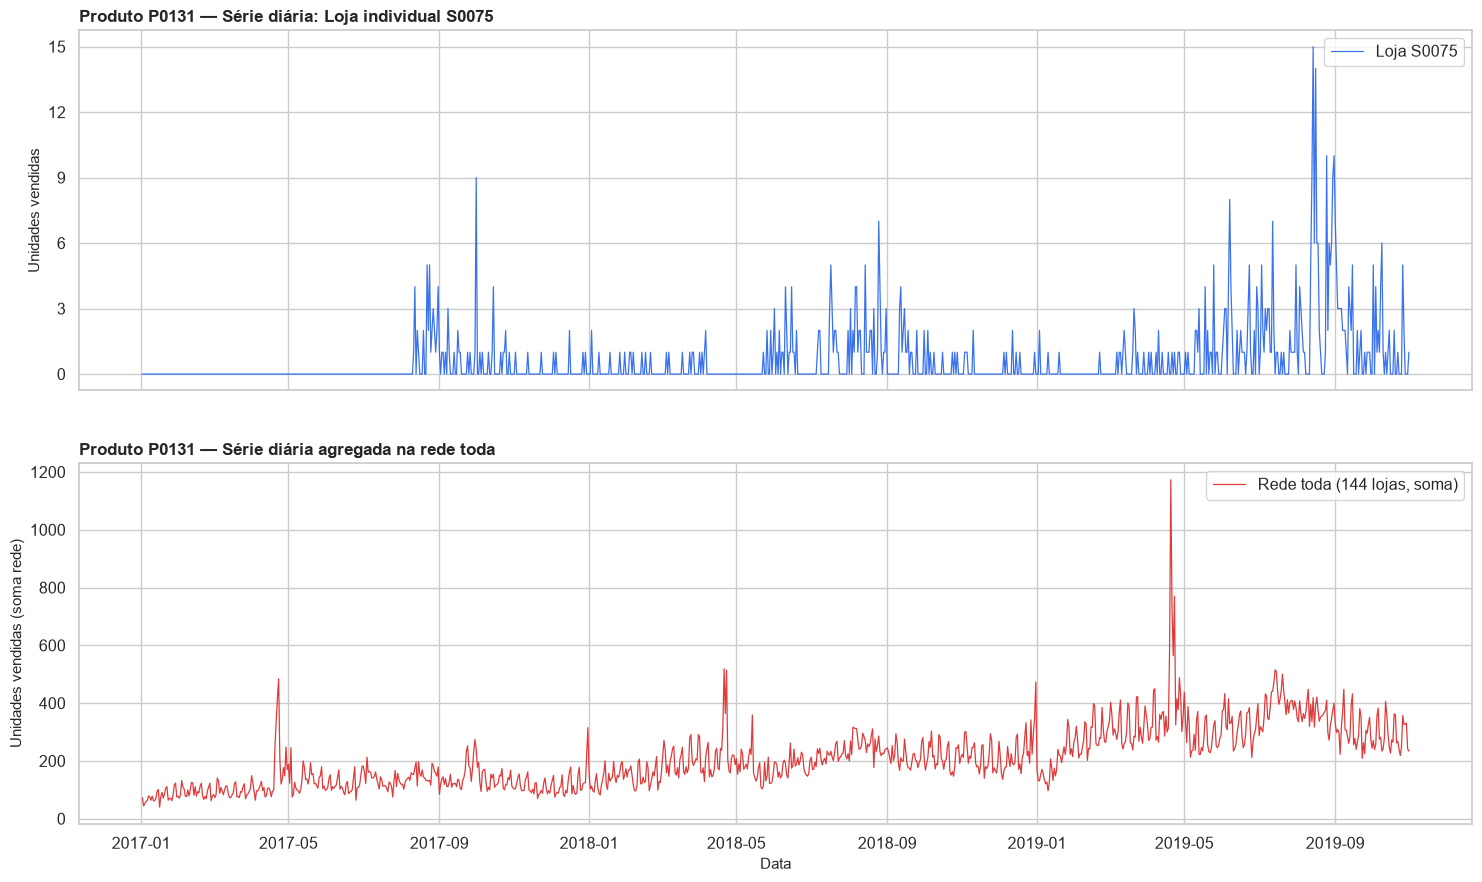

In [8]:
# 4. Plot serie diaria loja individual vs serie na rede
df_p_rede = df_rede[df_rede["produto"] == PRODUTO].set_index("data").sort_index()

# Escolhe uma loja: a que tem a media de vendas mais proxima da mediana das medias
media_mediana = loja_media.median()
loja_escolhida = (loja_media - media_mediana).abs().idxmin()
print(f"Loja escolhida para plot: {loja_escolhida} (media diaria = {loja_media[loja_escolhida]:.2f}, prox a mediana das lojas {media_mediana:.2f})")

df_loja_escolhida = df_p[df_p["loja"] == loja_escolhida].set_index("data").sort_index()

serie_loja = df_loja_escolhida["unidades"].reindex(df_p_rede.index, fill_value=0.0)
serie_rede = df_p_rede["unidades"]

# Faz o plot em 2 subplots empilhados (mesmo periodo, escalas diferentes)
sns.set_theme(style="whitegrid", font_scale=1.05)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

# Subplot 1: loja individual
ax1.plot(serie_loja.index, serie_loja.values,
         color="#2563EB", linewidth=0.9, alpha=0.9,
         label=f"Loja {loja_escolhida}")
ax1.set_ylabel("Unidades vendidas", fontsize=11)
ax1.set_title(f"Produto {PRODUTO} — Série diária: Loja individual {loja_escolhida}",
              fontsize=12, fontweight="bold", loc="left")
ax1.yaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=8))
ax1.legend(loc="upper right", frameon=True, fancybox=True)

# Subplot 2: serie agregada na rede toda
ax2.plot(serie_rede.index, serie_rede.values,
         color="#DC2626", linewidth=0.9, alpha=0.9,
         label="Rede toda (144 lojas, soma)")
ax2.set_ylabel("Unidades vendidas (soma rede)", fontsize=11)
ax2.set_xlabel("Data", fontsize=11)
ax2.set_title(f"Produto {PRODUTO} — Série diária agregada na rede toda",
              fontsize=12, fontweight="bold", loc="left")
ax2.yaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=8))
ax2.legend(loc="upper right", frameon=True, fancybox=True)

plt.tight_layout(h_pad=3)
caminho_plot = os.path.join(PASTA_FIGURAS, f"serie_comparativa_{PRODUTO}_loja_vs_rede.png")
plt.savefig(caminho_plot, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()


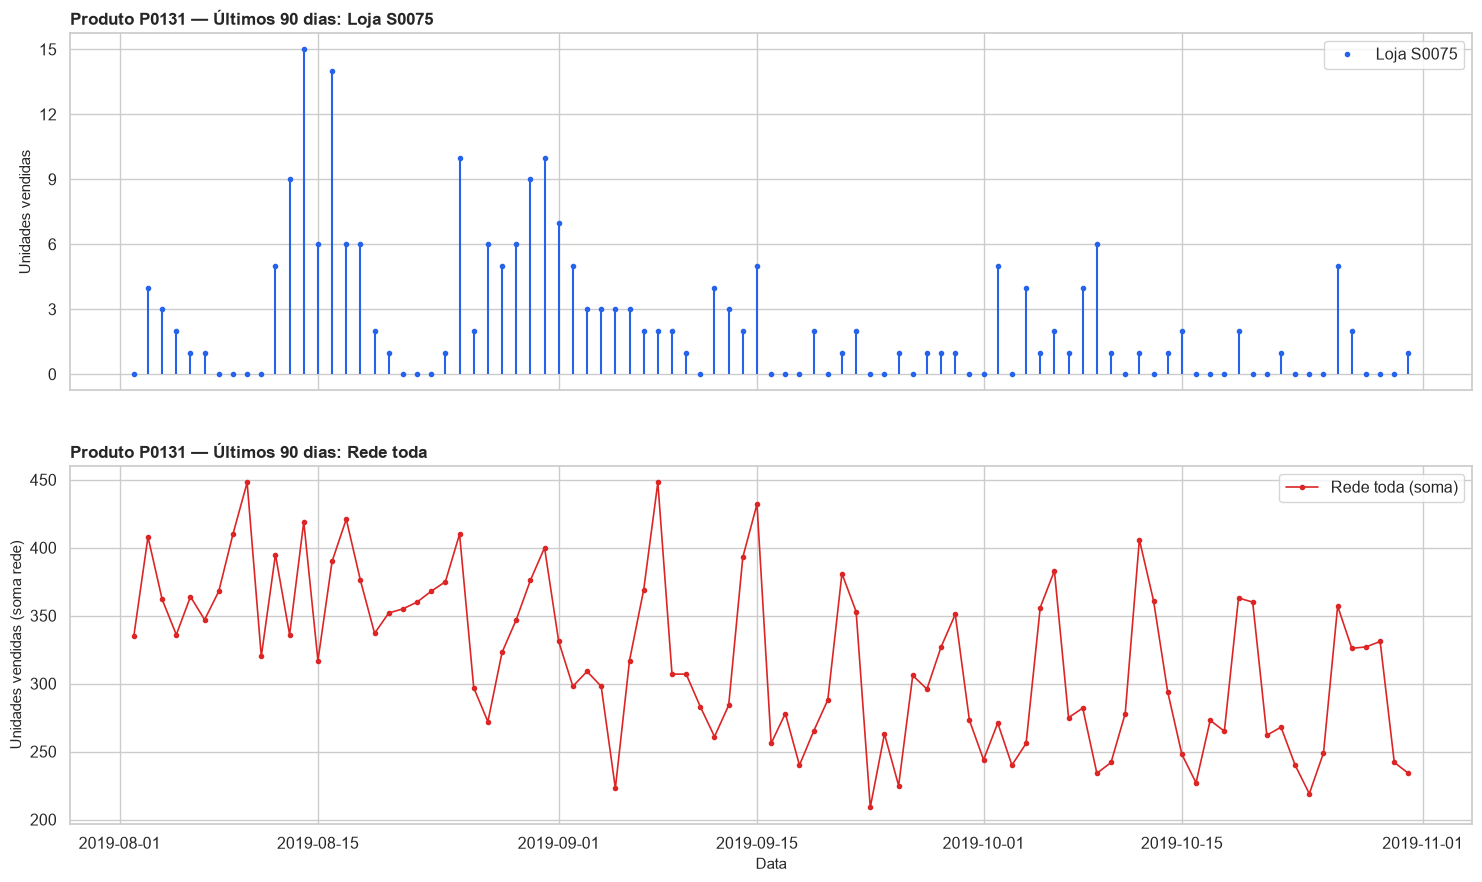


Plots salvos em:
  - 1: reports/figures\serie_comparativa_P0131_loja_vs_rede.png
  - 2: reports/figures\serie_comparativa_P0131_loja_vs_rede_90dias.png


In [9]:
# Segunda visualizacao: zoom em 90 dias para ver a granularidade
data_fim_zoom = df_p_rede.index.max()
data_inicio_zoom = data_fim_zoom - pd.Timedelta(days=90)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

idx_zoom = (serie_loja.index >= data_inicio_zoom) & (serie_loja.index <= data_fim_zoom)
markerline, stemlines, baseline = ax1.stem(
    serie_loja.index[idx_zoom], serie_loja.values[idx_zoom],
    basefmt=" ", linefmt="#2563EB"
)
plt.setp(markerline, markersize=3, color="#2563EB", marker="o")
ax1.set_ylabel("Unidades vendidas", fontsize=11)
ax1.set_title(f"Produto {PRODUTO} — Últimos 90 dias: Loja {loja_escolhida}",
              fontsize=12, fontweight="bold", loc="left")
ax1.yaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=6))
ax1.legend([markerline], [f"Loja {loja_escolhida}"], loc="upper right", frameon=True)

idx_zoom2 = (serie_rede.index >= data_inicio_zoom) & (serie_rede.index <= data_fim_zoom)
ax2.plot(serie_rede.index[idx_zoom2], serie_rede.values[idx_zoom2],
         color="#DC2626", linewidth=1.2, marker="o", markersize=3,
         label="Rede toda (soma)")
ax2.set_ylabel("Unidades vendidas (soma rede)", fontsize=11)
ax2.set_xlabel("Data", fontsize=11)
ax2.set_title(f"Produto {PRODUTO} — Últimos 90 dias: Rede toda",
              fontsize=12, fontweight="bold", loc="left")
ax2.yaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=6))
ax2.legend(loc="upper right", frameon=True)

plt.tight_layout(h_pad=3)
caminho_plot2 = os.path.join(PASTA_FIGURAS, f"serie_comparativa_{PRODUTO}_loja_vs_rede_90dias.png")
plt.savefig(caminho_plot2, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()

print()
print(f"Plots salvos em:")
print(f"  - 1: {caminho_plot}")
print(f"  - 2: {caminho_plot2}")


## 2.4 Série diária do produto foco P0131 (itens 1 a 4)

Série diária da rede para o P0131: período, vazios/zeros, média de venda, preço médio e a tendência
suavizada (média móvel centrada de 28 dias).


In [10]:
df = pd.read_csv(CAMINHO_REDE, sep=",", parse_dates=["data"], dayfirst=False)

PRODUTO = "P0131"

# Filtra e cria serie diaria com indice de data, frequencia explicita D
df_p = df[df["produto"] == PRODUTO].copy()
serie_p = (
    df_p.set_index("data")
    .sort_index()
    .asfreq("D")  # Garante frequencia diaria explicita; lacunas viram NaN
)

print(f"DECISAO REGISTRADA: Grão = produto x dia (base demanda.csv)")
print(f"                    demanda_por_loja.csv fora do escopo do projeto")
print(f"                    Produto foco: {PRODUTO}")
print("=" * 65)
print()

print(f"SERIE DO PRODUTO {PRODUTO}")
print("=" * 65)

# 1. Periodo
total_dias_idx = len(serie_p)
data_min = serie_p.index.min()
data_max = serie_p.index.max()
dias_calendario = (data_max - data_min).days + 1
print(f"ITEM 1:")
print(f"  Total de dias na serie (frequencia diaria explicita): {total_dias_idx}")
print(f"  Data inicial: {data_min.strftime('%d/%m/%Y')}")
print(f"  Data final  : {data_max.strftime('%d/%m/%Y')}")
print(f"  Dias corridos no periodo (inclui ambos os extremos): {dias_calendario}")
print()

# 2. Vazios e zeros
nan_unidades = serie_p["unidades"].isna().sum()
pct_nan = nan_unidades / total_dias_idx * 100
zeros_unidades = (serie_p["unidades"] == 0).sum()
pct_zeros = zeros_unidades / total_dias_idx * 100
nao_zero_nao_nan = ((serie_p["unidades"].notna()) & (serie_p["unidades"] > 0)).sum()
print(f"ITEM 2:")
print(f"  Dias com valor vazio (NaN em unidades): {nan_unidades}  ({pct_nan:.4f}%)")
print(f"  Dias com venda = 0 unidades          : {zeros_unidades}  ({pct_zeros:.4f}%)")
print(f"  Dias com venda > 0 unidades          : {nao_zero_nao_nan}  ({nao_zero_nao_nan/total_dias_idx*100:.4f}%)")
print()

# 3. Media de venda diaria e preco medio
venda_media = serie_p["unidades"].mean()
venda_soma_total = serie_p["unidades"].sum()
preco_medio_geral = serie_p["preco_medio"].mean()
preco_medio_ponderado = (
    (serie_p["preco_medio"] * serie_p["unidades"]).sum() / venda_soma_total
)
print(f"ITEM 3:")
print(f"  Venda media por dia (media simples sobre todos os dias, incluindo NaN=0): {venda_media:.4f} unidades/dia")
print(f"  Soma total de unidades no periodo: {venda_soma_total:,.1f}")
print(f"  Preco medio (media simples diaria): R$ {preco_medio_geral:.4f}")
print(f"  Preco medio ponderado por volume  : R$ {preco_medio_ponderado:.4f}")
print()

# Estatisticas descritivas da venda diaria
print("Distribuicao de unidades por dia:")
q = serie_p["unidades"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
q = q.round(3)
for k, v in q.items():
    print(f"  {k:>8}: {v:>10.3f}")
print()


DECISAO REGISTRADA: Grão = produto x dia (base demanda.csv)
                    demanda_por_loja.csv fora do escopo do projeto
                    Produto foco: P0131

SERIE DO PRODUTO P0131
ITEM 1:
  Total de dias na serie (frequencia diaria explicita): 1033
  Data inicial: 02/01/2017
  Data final  : 31/10/2019
  Dias corridos no periodo (inclui ambos os extremos): 1033

ITEM 2:
  Dias com valor vazio (NaN em unidades): 0  (0.0000%)
  Dias com venda = 0 unidades          : 0  (0.0000%)
  Dias com venda > 0 unidades          : 1033  (100.0000%)

ITEM 3:
  Venda media por dia (media simples sobre todos os dias, incluindo NaN=0): 208.0581 unidades/dia
  Soma total de unidades no periodo: 214,924.0
  Preco medio (media simples diaria): R$ 2.5870
  Preco medio ponderado por volume  : R$ 2.7183

Distribuicao de unidades por dia:
     count:   1033.000
      mean:    208.058
       std:    105.145
       min:     40.000
       10%:     96.000
       25%:    125.000
       50%:    190.000
   

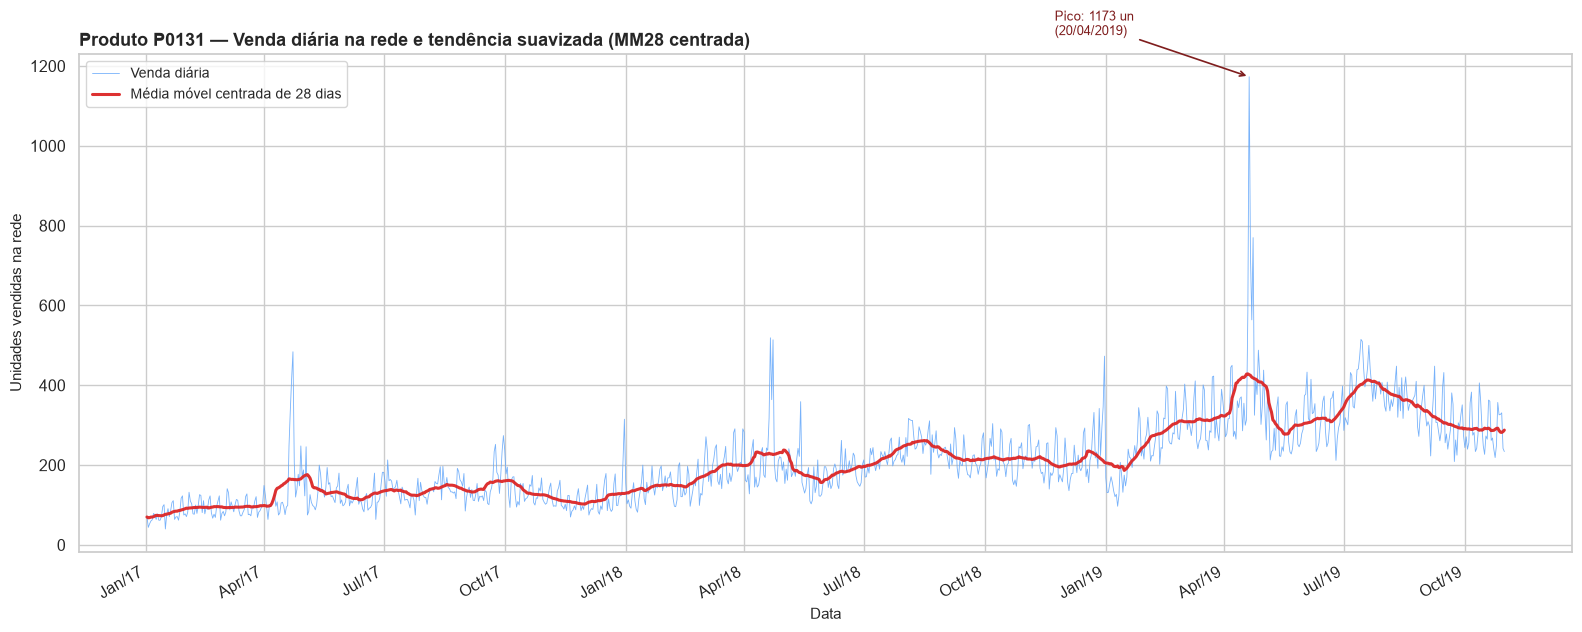

ITEM 4:
  Plot salvo em: reports/figures\venda_diaria_P0131_MM28centrada.png
  Janela MM28 = 1033 pontos com MM calculada (min_periods=14 nas bordas)
  Pico diário da série = 1173 unidades em 20/04/2019
  Min  diário da série = 40 unidades


In [11]:
# 4. Plot venda diaria + media movel centrada de 28 dias
mm_28_centrada = serie_p["unidades"].rolling(window=28, center=True, min_periods=14).mean()

sns.set_theme(style="whitegrid", font_scale=1.05)
fig, ax = plt.subplots(figsize=(16, 6.5))

ax.plot(serie_p.index, serie_p["unidades"].values,
        color="#60A5FA", linewidth=0.6, alpha=0.85,
        label="Venda diária")
ax.plot(mm_28_centrada.index, mm_28_centrada.values,
        color="#DC2626", linewidth=2.2, alpha=0.95,
        label="Média móvel centrada de 28 dias")

ax.set_title(f"Produto {PRODUTO} — Venda diária na rede e tendência suavizada (MM28 centrada)",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Data", fontsize=11)
ax.set_ylabel("Unidades vendidas na rede", fontsize=11)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b/%y"))
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

dias_ferias = ax.get_lines()[1]
ax.legend(loc="upper left", frameon=True, fancybox=True, fontsize=10)

# Destaque da faixa promocional / pico principal
max_venda = serie_p["unidades"].max()
data_pico = serie_p["unidades"].idxmax()
ax.annotate(f"Pico: {max_venda:.0f} un\n({data_pico.strftime('%d/%m/%Y')})",
            xy=(data_pico, max_venda),
            xytext=(-140, 30), textcoords="offset points",
            fontsize=9, color="#7F1D1D",
            arrowprops=dict(arrowstyle="->", color="#7F1D1D", lw=1.2))

plt.tight_layout()
caminho_plot = os.path.join(PASTA_FIGURAS, f"venda_diaria_{PRODUTO}_MM28centrada.png")
plt.savefig(caminho_plot, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()

print(f"ITEM 4:")
print(f"  Plot salvo em: {caminho_plot}")
print(f"  Janela MM28 = {mm_28_centrada.notna().sum()} pontos com MM calculada "
      f"(min_periods=14 nas bordas)")
print(f"  Pico diário da série = {max_venda:.0f} unidades em {data_pico.strftime('%d/%m/%Y')}")
print(f"  Min  diário da série = {serie_p['unidades'].min():.0f} unidades")


## 2.5 Ciclo semanal e ciclo anual do P0131

Testamos a existência de **sazonalidade semanal** (venda média por dia da semana; dias úteis vs fim de
semana) e investigamos indícios de **ciclo anual** (média mensal ao longo do histórico).


In [12]:
df = pd.read_csv(CAMINHO_REDE, sep=",", parse_dates=["data"], dayfirst=False)
PRODUTO = "P0131"

serie_p = (
    df[df["produto"] == PRODUTO]
    .set_index("data")
    .sort_index()
    .asfreq("D")
)

media_geral = serie_p["unidades"].mean()
print(f"Produto {PRODUTO}")
print(f"Media geral de venda diaria: {media_geral:.4f} unidades")
print()

# --- Item 1: Venda media por dia da semana + plot ---
dias_semana_pt = [
    "2a-feira", "3a-feira", "4a-feira", "5a-feira",
    "6a-feira", "Sabado", "Domingo"
]

serie_p["dow"] = serie_p.index.dayofweek  # 0=seg ... 6=dom
serie_p["dia_semana_nome"] = serie_p["dow"].map(
    lambda d: dias_semana_pt[d]
)

venda_por_dow = serie_p.groupby("dow")["unidades"].agg([
    "mean", "median", "std", "count"
]).rename(columns={
    "mean": "media", "median": "mediana", "std": "desv_p", "count": "n"
})
venda_por_dow["desv_p_pct_da_media"] = (
    venda_por_dow["desv_p"] / venda_por_dow["media"] * 100
).round(2)
venda_por_dow["nome"] = dias_semana_pt
venda_por_dow = venda_por_dow[["nome", "n", "media", "mediana", "desv_p", "desv_p_pct_da_media"]]

print("ITEM 1: Venda media por dia da semana")
print("=" * 65)
print(venda_por_dow.round(3).to_string())
print()
print("Diferenca percentual em relacao a media geral ({}):".format(
    round(media_geral, 2)))
for d in range(7):
    m = venda_por_dow.loc[d, "media"]
    pct = (m - media_geral) / media_geral * 100
    print(f"  {dias_semana_pt[d]:>10}: {m:>7.2f}  ({pct:+.2f}%)")
print()


Produto P0131
Media geral de venda diaria: 208.0581 unidades

ITEM 1: Venda media por dia da semana
         nome    n    media  mediana   desv_p  desv_p_pct_da_media
dow                                                               
0    2a-feira  148  191.142    171.0  100.122                52.38
1    3a-feira  148  185.020    170.5   96.322                52.06
2    4a-feira  148  183.000    166.5   83.830                45.81
3    5a-feira  148  189.365    173.5   88.975                46.99
4    6a-feira  147  205.095    194.0   94.476                46.06
5      Sabado  147  253.435    241.0  131.173                51.76
6     Domingo  147  249.918    231.0  108.940                43.59

Diferenca percentual em relacao a media geral (208.06):
    2a-feira:  191.14  (-8.13%)
    3a-feira:  185.02  (-11.07%)
    4a-feira:  183.00  (-12.04%)
    5a-feira:  189.36  (-8.98%)
    6a-feira:  205.10  (-1.42%)
      Sabado:  253.44  (+21.81%)
     Domingo:  249.92  (+20.12%)



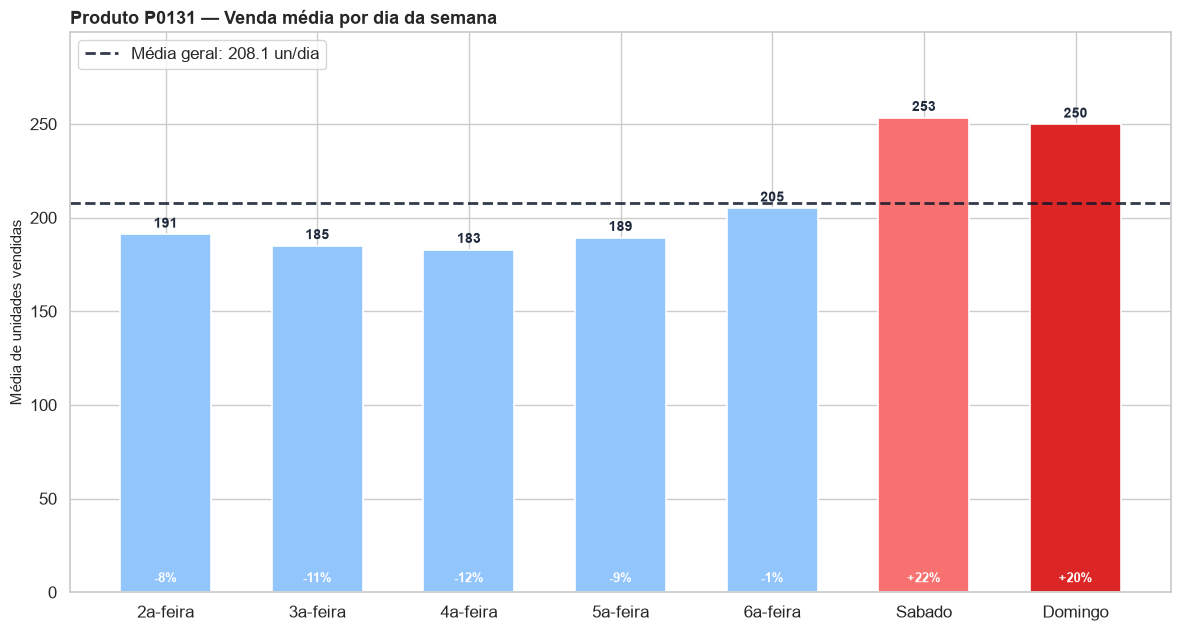

  Plot salvo em: reports/figures\venda_media_dia_semana_P0131.png



In [13]:
# Plot barras
sns.set_theme(style="whitegrid", font_scale=1.08)
cores = ["#93C5FD"] * 5 + ["#F87171", "#DC2626"]  # util azul claro, fim semana vermelho

fig, ax = plt.subplots(figsize=(12, 6.5))
bars = ax.bar(
    venda_por_dow["nome"], venda_por_dow["media"],
    color=cores, edgecolor="white", linewidth=1.2, width=0.6
)

# Linha horizontal da media geral
ax.axhline(media_geral, color="#0F172A", linestyle="--", linewidth=2, alpha=0.85,
           label=f"Média geral: {media_geral:.1f} un/dia")

# Rotulos acima das barras
for bar, val in zip(bars, venda_por_dow["media"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
            f"{val:.0f}", ha="center", va="bottom", fontsize=10,
            fontweight="bold", color="#1E293B")

# Diferencas percentual no rodapé da barra
for bar, d in zip(bars, range(7)):
    m = venda_por_dow.loc[d, "media"]
    pct = (m - media_geral) / media_geral * 100
    rotulo = f"{pct:+.0f}%"
    ax.text(bar.get_x() + bar.get_width() / 2, 4, rotulo,
            ha="center", va="bottom", fontsize=9, color="white",
            fontweight="bold")

ax.set_ylabel("Média de unidades vendidas", fontsize=11)
ax.set_title(f"Produto {PRODUTO} — Venda média por dia da semana",
             fontsize=13, fontweight="bold", loc="left")
ax.legend(loc="upper left", frameon=True, fancybox=True)
ax.set_ylim(0, max(venda_por_dow["media"]) * 1.18)

caminho_plot1 = os.path.join(PASTA_FIGURAS, f"venda_media_dia_semana_{PRODUTO}.png")
plt.tight_layout()
plt.savefig(caminho_plot1, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()
print(f"  Plot salvo em: {caminho_plot1}")
print()


In [14]:
# --- Item 2: Media dias uteis vs sabado vs domingo vs fim de semana ---
print("ITEM 2: Comparação dia útil vs fim de semana")
print("=" * 65)

serie_p["eh_util"] = serie_p["dow"] <= 4  # seg=0 ... sex=4
serie_p["grupo_dia"] = serie_p["dow"].map(lambda d:
    "Dias úteis (seg-sex)" if d <= 4 else
    "Sábado" if d == 5 else "Domingo"
)

grupo_dia = serie_p.groupby("grupo_dia")["unidades"].agg([
    "mean", "median", "std", "count"
]).reindex(["Dias úteis (seg-sex)", "Sábado", "Domingo"])
grupo_dia["razao_vs_uteis"] = grupo_dia["mean"] / grupo_dia.loc["Dias úteis (seg-sex)", "mean"]
grupo_dia = grupo_dia.round(4)
print(grupo_dia.to_string())
print()

media_uteis = grupo_dia.loc["Dias úteis (seg-sex)", "mean"]
media_sab = grupo_dia.loc["Sábado", "mean"]
media_dom = grupo_dia.loc["Domingo", "mean"]
media_fds = serie_p.loc[serie_p["dow"] >= 5, "unidades"].mean()

print(f"  Media dias úteis     : {media_uteis:.2f}")
print(f"  Media sábado         : {media_sab:.2f}  ({media_sab/media_uteis:.2f}x o dia útil)")
print(f"  Media domingo        : {media_dom:.2f}  ({media_dom/media_uteis:.2f}x o dia útil)")
print(f"  Media fim de semana  : {media_fds:.2f}  ({media_fds/media_uteis:.2f}x o dia útil, média simples sab+dom)")
print()

# --- Item 3: Ciclo anual (resposta em texto + indicativo numerico) ---
print("ITEM 3: Indícios de ciclo anual")
print("=" * 65)
n_meses_completos = serie_p.resample("ME")["unidades"].mean()
print(f"Numero de meses no historico: {len(n_meses_completos)} meses  "
      f"({serie_p.index[0].strftime('%b/%y')} a {serie_p.index[-1].strftime('%b/%y')})")
print(f"Anos completos fechados: 2 (2017 e 2018). 2019 vai só até outubro.")
print()

# Media por mes do ano (jan a dez) combinando todos os anos
serie_p["mes"] = serie_p.index.month
mes_nomes = ["jan", "fev", "mar", "abr", "mai", "jun",
             "jul", "ago", "set", "out", "nov", "dez"]
venda_por_mes_ano = serie_p.groupby(["mes", serie_p.index.year])["unidades"].mean().unstack()
venda_por_mes_ano.index = [mes_nomes[i - 1] for i in venda_por_mes_ano.index]

media_mes = serie_p.groupby("mes")["unidades"].mean()
media_mes.index = mes_nomes
pct_mes_vs_media_geral = (media_mes - media_geral) / media_geral * 100

df_mes = pd.DataFrame({
    "media_diaria_por_mes": media_mes.round(2),
    "%_vs_media_geral": pct_mes_vs_media_geral.round(2)
})
print("Media diaria por mês do ano (todos os anos combinados):")
print(df_mes.to_string())
print()


ITEM 2: Comparação dia útil vs fim de semana
                          mean  median       std  count  razao_vs_uteis
grupo_dia                                                              
Dias úteis (seg-sex)  190.7050   175.0   92.9906    739          1.0000
Sábado                253.4354   241.0  131.1733    147          1.3289
Domingo               249.9184   231.0  108.9401    147          1.3105

  Media dias úteis     : 190.71
  Media sábado         : 253.44  (1.33x o dia útil)
  Media domingo        : 249.92  (1.31x o dia útil)
  Media fim de semana  : 251.68  (1.32x o dia útil, média simples sab+dom)

ITEM 3: Indícios de ciclo anual
Numero de meses no historico: 34 meses  (Jan/17 a Oct/19)
Anos completos fechados: 2 (2017 e 2018). 2019 vai só até outubro.

Media diaria por mês do ano (todos os anos combinados):
     media_diaria_por_mes  %_vs_media_geral
jan                136.40            -34.44
fev                174.94            -15.92
mar                204.99           

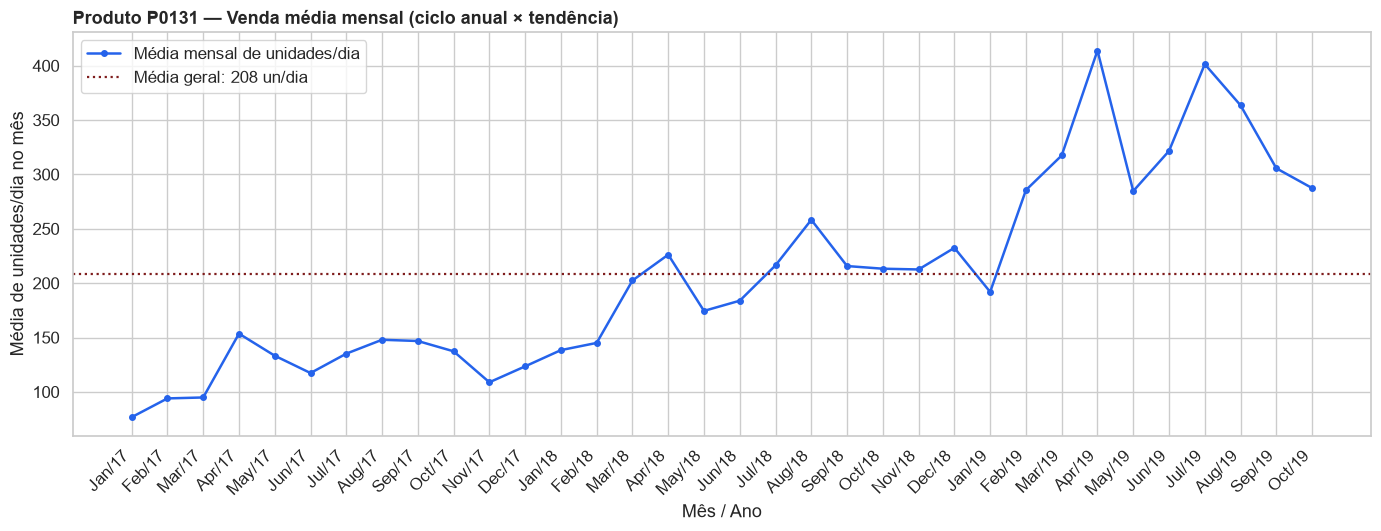

  Plot mensal salvo em: reports/figures\serie_mensal_P0131_ciclo_anual.png


In [15]:
# Serie mensal: media mensal (jan/17 a out/19) para visualizar ciclo
fig, ax = plt.subplots(figsize=(14, 5.5))
n_meses_completos.index = [d.strftime("%b/%y") for d in n_meses_completos.index]
ax.plot(n_meses_completos.index, n_meses_completos.values,
        marker="o", color="#2563EB", linewidth=1.8, markersize=4,
        label="Média mensal de unidades/dia")

ax.set_title(f"Produto {PRODUTO} — Venda média mensal (ciclo anual × tendência)",
             fontsize=13, fontweight="bold", loc="left")
ax.set_ylabel("Média de unidades/dia no mês")
ax.set_xlabel("Mês / Ano")
ax.axhline(media_geral, color="#7F1D1D", linestyle=":", linewidth=1.6,
           label=f"Média geral: {media_geral:.0f} un/dia")
plt.xticks(rotation=45, ha="right")
ax.legend(loc="upper left", frameon=True, fancybox=True)
plt.tight_layout()
caminho_plot2 = os.path.join(PASTA_FIGURAS, f"serie_mensal_{PRODUTO}_ciclo_anual.png")
plt.savefig(caminho_plot2, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()
print(f"  Plot mensal salvo em: {caminho_plot2}")


## 2.6 Decomposição STL do P0131 (período = 7, robusta)

Decompomos a série em tendência, sazonalidade e resíduo (STL com período 7 e `robust=True`) e medimos a
**força da tendência** e a **força da sazonalidade** pela fórmula de Hyndman:

- `F_tendência = max(0, 1 − Var(resíduo) / Var(tendência + resíduo))`
- `F_sazonalidade = max(0, 1 − Var(resíduo) / Var(sazonalidade + resíduo))`

Regra prática: força > 0,64 é considerada "forte".


In [16]:
PRODUTO = "P0131"
PERIODO_SAZONAL = 7  # semanal

df = pd.read_csv(CAMINHO_REDE, sep=",", parse_dates=["data"], dayfirst=False)
serie = (
    df[df["produto"] == PRODUTO]
    .set_index("data")
    .sort_index()["unidades"]
    .asfreq("D")
)

# --- Decomposicao STL ---
stl = STL(
    serie,
    period=PERIODO_SAZONAL,
    seasonal=13,        # impar default; robust=True usa procedimento robusto
    trend=None,
    low_pass=None,
    seasonal_deg=1,
    trend_deg=1,
    low_pass_deg=1,
    robust=True          # Item pede versao robusta
)
res = stl.fit()

observado = res.observed
tendencia = res.trend
sazonal = res.seasonal
residuo = res.resid

print(f"Produto {PRODUTO} — Decomposição STL, período={PERIODO_SAZONAL}, robust=True")
print("=" * 65)
print()

# --- Item 2: Forca da tendencia e forca da sazonalidade (Hyndman) ---
# Formula Hyndman & Athanasopoulos (Forecasting: Principles and Practice):
# F_tend = max(0, 1 - Var(residuo) / Var(tendencia + residuo))
# F_saz  = max(0, 1 - Var(residuo) / Var(sazonal   + residuo))
var_residuo = np.var(residuo, ddof=1)
var_residuo_mais_tend = np.var(tendencia + residuo, ddof=1)
var_residuo_mais_saz = np.var(sazonal + residuo, ddof=1)

forca_tend = max(0.0, 1 - var_residuo / var_residuo_mais_tend)
forca_saz = max(0.0, 1 - var_residuo / var_residuo_mais_saz)

print("ITEM 2: Força da tendência e força da sazonalidade (Hyndman)")
print("-" * 65)
print(f"  Var(resíduo)                         : {var_residuo:>12.3f}")
print(f"  Var(tendência + resíduo)             : {var_residuo_mais_tend:>12.3f}")
print(f"  Var(sazonalidade + resíduo)          : {var_residuo_mais_saz:>12.3f}")
print()
print(f"  Força da TENDÊNCIA    (F_t) = 1 - Var(r)/Var(T+r) = {forca_tend:.6f}  "
      f"({forca_tend*100:.2f}%)")
print(f"  Força da SAZONALIDADE (F_s) = 1 - Var(r)/Var(S+r) = {forca_saz:.6f}  "
      f"({forca_saz*100:.2f}%)")
print()
print("Interpretação rápida (regra Hyndman):")
print(f"  F_t > 0.64 = tendência 'forte'      : {'SIM' if forca_tend > 0.64 else 'NAO'}")
print(f"  F_s > 0.64 = sazonalidade 'forte'   : {'SIM' if forca_saz > 0.64 else 'NAO'}")
print()


Produto P0131 — Decomposição STL, período=7, robust=True

ITEM 2: Força da tendência e força da sazonalidade (Hyndman)
-----------------------------------------------------------------
  Var(resíduo)                         :     1414.387
  Var(tendência + resíduo)             :    10070.737
  Var(sazonalidade + resíduo)          :     2413.405

  Força da TENDÊNCIA    (F_t) = 1 - Var(r)/Var(T+r) = 0.859555  (85.96%)
  Força da SAZONALIDADE (F_s) = 1 - Var(r)/Var(S+r) = 0.413945  (41.39%)

Interpretação rápida (regra Hyndman):
  F_t > 0.64 = tendência 'forte'      : SIM
  F_s > 0.64 = sazonalidade 'forte'   : NAO



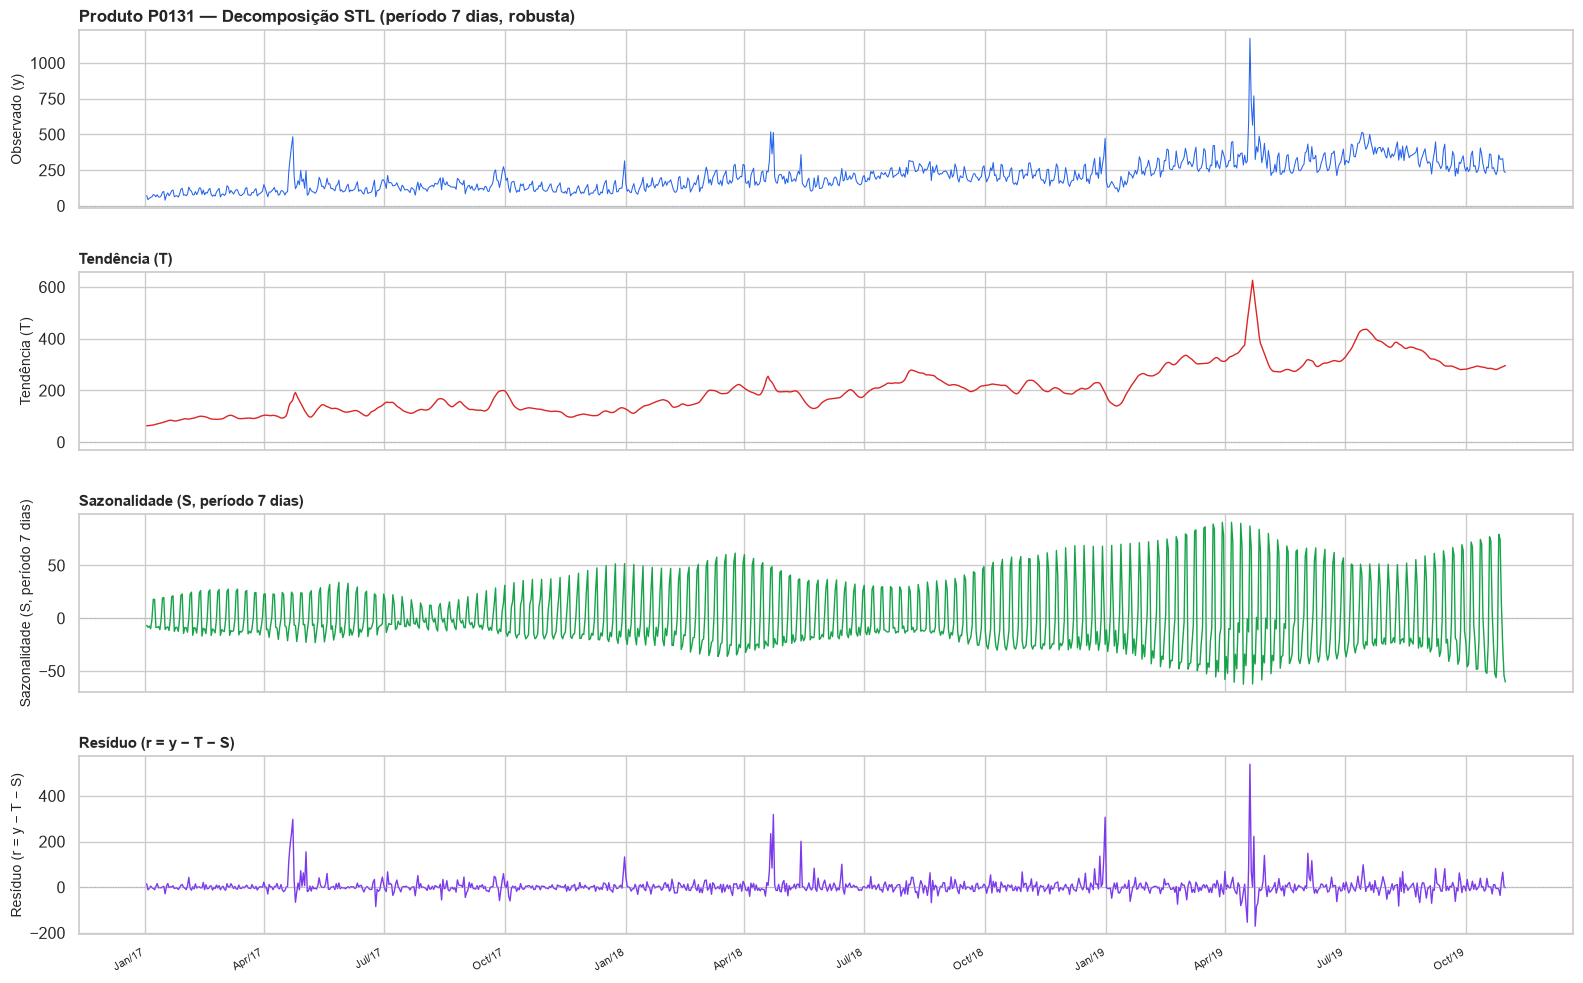

ITEM 1: 4 painéis salvos em: reports/figures\decomposicao_stl_P0131_p7.png



In [17]:
# --- Item 1: 4 paineis (observado, tendencia, sazonal, residuo) ---
sns.set_theme(style="whitegrid", font_scale=1.02)

fig, axes = plt.subplots(4, 1, figsize=(16, 10), sharex=True)

series_painel = [
    ("Observado (y)",  observado, "#2563EB"),
    ("Tendência (T)",  tendencia, "#DC2626"),
    ("Sazonalidade (S, período 7 dias)", sazonal, "#16A34A"),
    ("Resíduo (r = y − T − S)", residuo, "#7C3AED"),
]

for ax, (tit, vals, cor) in zip(axes, series_painel):
    ax.plot(vals.index, vals.values, color=cor, linewidth=1.0 if tit != "Observado (y)" else 0.75)
    ax.axhline(0, color="#94A3B8", linewidth=0.7, linestyle=":", alpha=0.8)
    ax.set_ylabel(tit, fontsize=10)
    ax.set_title(tit, loc="left", fontsize=11, fontweight="bold")
    ax.tick_params(axis="x", labelsize=8)

axes[0].set_title(f"Produto {PRODUTO} — Decomposição STL (período {PERIODO_SAZONAL} dias, robusta)",
                  loc="left", fontsize=12, fontweight="bold", pad=6)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b/%y"))
plt.setp(axes[-1].get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(h_pad=2.2)

caminho_plot1 = os.path.join(PASTA_FIGURAS, f"decomposicao_stl_{PRODUTO}_p{PERIODO_SAZONAL}.png")
plt.savefig(caminho_plot1, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()
print(f"ITEM 1: 4 painéis salvos em: {caminho_plot1}")
print()


In [18]:
# --- Item 3: Descrever o residuo (numeros auxiliares, sem especular) ---
print("ITEM 3: Descrição do painel de resíduo (medidas descritivas)")
print("-" * 65)
print(f"  Média do resíduo          : {residuo.mean():>+.4f}")
print(f"  Mediana do resíduo        : {np.median(residuo):>+.4f}")
print(f"  Desvio padrão (amostral)  : {residuo.std(ddof=1):>+.4f}")
print(f"  Min                       : {residuo.min():>+.4f}")
print(f"  Max                       : {residuo.max():>+.4f}")
q = np.quantile(residuo, [0.01, 0.05, 0.25, 0.75, 0.95, 0.99])
print(f"  Q01 / Q05 / Q25 / Q75 / Q95 / Q99 : "
      f"{q[0]:>+8.2f} / {q[1]:>+8.2f} / {q[2]:>+8.2f} / {q[3]:>+8.2f} / {q[4]:>+8.2f} / {q[5]:>+8.2f}")
# Amplitude interquartil e faixa de 3x sigma
iqr = q[3] - q[2]
lim_inf = q[2] - 3 * iqr
lim_sup = q[3] + 3 * iqr
n_fora_iqr = ((residuo < lim_inf) | (residuo > lim_sup)).sum()
lim_sigma = 3 * residuo.std(ddof=1)
n_fora_3sigma = (residuo.abs() > lim_sigma).sum()
print(f"  IQR = {iqr:.2f};  Observados fora ±3·IQR : {n_fora_iqr} de {len(residuo)}  ({n_fora_iqr/len(residuo)*100:.3f}%)")
print(f"  σ   = {residuo.std(ddof=1):.2f}; Observados fora ±3·σ   : {n_fora_3sigma} de {len(residuo)}  ({n_fora_3sigma/len(residuo)*100:.3f}%)")

# Top 10 picos (5 positivos + 5 negativos)
idx_top_pos = np.argsort(-residuo.values)[:5]
idx_top_neg = np.argsort(residuo.values)[:5]
print()
print("  5 maiores picos positivos (resíduo >> 0):")
for i in idx_top_pos:
    d = residuo.index[i]
    v = residuo.iloc[i]
    y = observado.iloc[i]
    print(f"    {d.strftime('%d/%m/%Y')}  residuo={v:>+8.1f}   observado={y:>6.0f}")
print("  5 maiores picos negativos (resíduo << 0):")
for i in idx_top_neg:
    d = residuo.index[i]
    v = residuo.iloc[i]
    y = observado.iloc[i]
    print(f"    {d.strftime('%d/%m/%Y')}  residuo={v:>+8.1f}   observado={y:>6.0f}")


ITEM 3: Descrição do painel de resíduo (medidas descritivas)
-----------------------------------------------------------------
  Média do resíduo          : +3.7260
  Mediana do resíduo        : +0.0105
  Desvio padrão (amostral)  : +37.6083
  Min                       : -170.5733
  Max                       : +538.6332
  Q01 / Q05 / Q25 / Q75 / Q95 / Q99 :   -67.59 /   -29.67 /    -9.57 /   +10.82 /   +43.74 /  +145.71
  IQR = 20.39;  Observados fora ±3·IQR : 35 de 1033  (3.388%)
  σ   = 37.61; Observados fora ±3·σ   : 19 de 1033  (1.839%)

  5 maiores picos positivos (resíduo >> 0):
    20/04/2019  residuo=  +538.6   observado=  1173
    23/04/2018  residuo=  +318.7   observado=   514
    31/12/2018  residuo=  +306.7   observado=   473
    23/04/2017  residuo=  +297.5   observado=   484
    22/04/2017  residuo=  +236.1   observado=   417
  5 maiores picos negativos (resíduo << 0):
    24/04/2019  residuo=  -170.6   observado=   325
    18/04/2019  residuo=  -153.4   observado=   314


## 2.7 Triagem dos 30 produtos (itens 1 a 3)

Para cada produto, calculamos a razão entre a **média diária dos últimos 90 dias** e a **média do período
anterior (de 455 a 90 dias antes do fim)**. Razões muito baixas (< 0,6) sinalizam produto que perdeu volume
de forma estrutural — candidato a descontinuação, e que **não deveria entrar no escopo** de um modelo de
previsão. A remoção efetiva é decidida e aplicada na Fase 3.


In [19]:
df = pd.read_csv(CAMINHO_REDE, sep=",", parse_dates=["data"], dayfirst=False)

# Monta painel wide: indice data, colunas = produtos, valores = unidades
painel = (
    df.pivot_table(index="data", columns="produto", values="unidades", aggfunc="sum")
    .sort_index()
    .asfreq("D")  # frequencia diaria; lacunas (se houver) viram NaN
)

data_max = painel.index.max()
fim_janela_recente = data_max
inicio_janela_recente = data_max - pd.Timedelta(days=89)  # 90 dias inclusivo: 89 + 1 = 90

fim_janela_anterior = data_max - pd.Timedelta(days=90)
inicio_janela_anterior = data_max - pd.Timedelta(days=454)  # 455 dias inclusivo: 454 + 1 = 455

print(f"Data maxima da base: {data_max.strftime('%d/%m/%Y')}")
print(f"Janela RECENTE (ultimos 90 dias): "
      f"{inicio_janela_recente.strftime('%d/%m/%Y')} a {fim_janela_recente.strftime('%d/%m/%Y')}")
print(f"Janela ANTERIOR (455 a 90 dias atras): "
      f"{inicio_janela_anterior.strftime('%d/%m/%Y')} a {fim_janela_anterior.strftime('%d/%m/%Y')}")
print()

# --- Item 1: Calculo da razao por produto ---
resultados = []
for produto in painel.columns:
    serie = painel[produto]
    serie_recente = serie.loc[inicio_janela_recente:fim_janela_recente]
    serie_anterior = serie.loc[inicio_janela_anterior:fim_janela_anterior]
    media_recente = serie_recente.mean(skipna=True)
    media_anterior = serie_anterior.mean(skipna=True)
    n_recente_valido = serie_recente.notna().sum()
    n_anterior_valido = serie_anterior.notna().sum()
    razao = media_recente / media_anterior if media_anterior > 0 else np.nan
    resultados.append({
        "produto": produto,
        "media_recente_90d": round(media_recente, 4),
        "media_anterior_455_90d": round(media_anterior, 4),
        "razao_recente_sobre_anterior": round(razao, 6) if not np.isnan(razao) else np.nan,
        "n_dias_validos_recente": n_recente_valido,
        "n_dias_validos_anterior": n_anterior_valido,
    })

df_triagem = pd.DataFrame(resultados).sort_values(
    "razao_recente_sobre_anterior", ascending=True, na_position="first"
).reset_index(drop=True)

# Marca a linha do produto foco
foco = "P0131"
df_triagem.insert(1, "eh_foco", df_triagem["produto"] == foco)
formato_flag = lambda x: "← Foco P0131" if x else ""
df_triagem["eh_foco"] = df_triagem["eh_foco"].map(formato_flag)

print("ITEM 1: Tabela completa de razão (média recente 90d) / (média do período 455–90 dias atrás)")
print("         Ordenada por razão CRESCENTE (menores razões no topo)")
print("=" * 90)
print(df_triagem.round(4).to_string(index=False))
print()

n_total = len(df_triagem)
print("6 MENORES razões (risco de produto morto / descontinuado):")
print("-" * 90)
print(df_triagem[["produto", "media_recente_90d", "media_anterior_455_90d",
                   "razao_recente_sobre_anterior", "n_dias_validos_recente",
                   "n_dias_validos_anterior", "eh_foco"]].head(6).to_string(index=False))
print()
print("3 MAIORES razões (produto crescendo):")
print("-" * 90)
print(df_triagem[["produto", "media_recente_90d", "media_anterior_455_90d",
                   "razao_recente_sobre_anterior", "n_dias_validos_recente",
                   "n_dias_validos_anterior", "eh_foco"]].tail(3).iloc[::-1].to_string(index=False))
print()
print(f"Produto foco P0131 — posicao no ranking (1 menor a {n_total} maior): "
      f"{int(df_triagem.reset_index().query(f'produto == \"{foco}\"').index[0]) + 1}")
print()


Data maxima da base: 31/10/2019
Janela RECENTE (ultimos 90 dias): 03/08/2019 a 31/10/2019
Janela ANTERIOR (455 a 90 dias atras): 03/08/2018 a 02/08/2019

ITEM 1: Tabela completa de razão (média recente 90d) / (média do período 455–90 dias atrás)
         Ordenada por razão CRESCENTE (menores razões no topo)
produto      eh_foco  media_recente_90d  media_anterior_455_90d  razao_recente_sobre_anterior  n_dias_validos_recente  n_dias_validos_anterior
  P0438                          0.0455                274.4933                        0.0002                      22                      300
  P0051                         28.3667                263.3123                        0.1077                      90                      365
  P0079                          4.3222                 31.4521                        0.1374                      90                      365
  P0590                        114.6778                142.1836                        0.8065                      90  

ITEM 2: Produtos com razão < 0.6 (3 produto(s)):
  - P0438: razão = 0.0002  |  média recente = 0.05  |  média anterior = 274.49
  - P0051: razão = 0.1077  |  média recente = 28.37  |  média anterior = 263.31
  - P0079: razão = 0.1374  |  média recente = 4.32  |  média anterior = 31.45



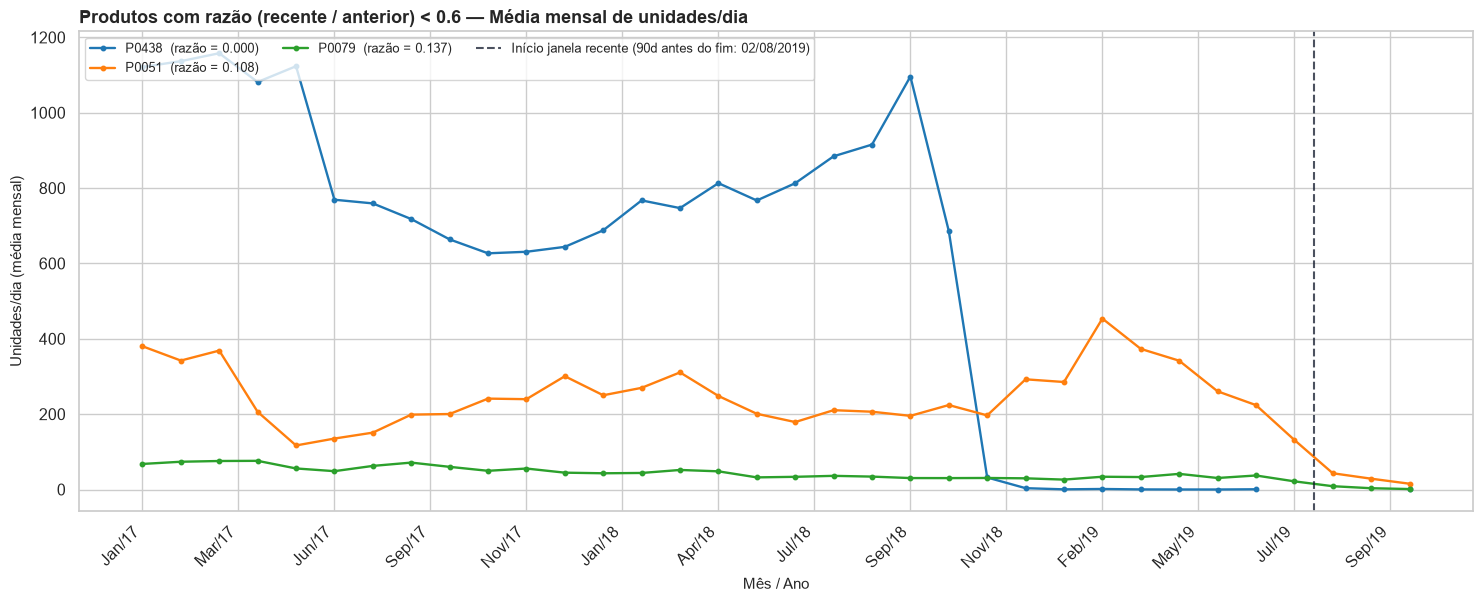

  Plot salvo em: reports/figures\triagem_produtos_razao_abaixo_0_6.png



In [20]:
# --- Item 2: Plote media mensal dos produtos com razao < 0,6 ---
LIMIAR = 0.6
produtos_criticos = df_triagem.loc[
    df_triagem["razao_recente_sobre_anterior"] < LIMIAR, "produto"
].tolist()
print(f"ITEM 2: Produtos com razão < {LIMIAR} ({len(produtos_criticos)} produto(s)):")
for p in produtos_criticos:
    r = df_triagem.loc[df_triagem["produto"] == p, "razao_recente_sobre_anterior"].iloc[0]
    mr = df_triagem.loc[df_triagem["produto"] == p, "media_recente_90d"].iloc[0]
    ma = df_triagem.loc[df_triagem["produto"] == p, "media_anterior_455_90d"].iloc[0]
    print(f"  - {p}: razão = {r:.4f}  |  média recente = {mr:.2f}  |  média anterior = {ma:.2f}")
print()

if len(produtos_criticos) == 0:
    print("Nenhum produto abaixo do limiar. Nada a plotar.")
else:
    # Media mensal para cada produto critico, mantendo como serie temporal
    painel_mensal = (
        painel[produtos_criticos]
        .resample("ME")
        .mean()
    )

    # Formata eixo x como "Mes/Ano"
    eixo_x = [d.strftime("%b/%y") for d in painel_mensal.index]

    sns.set_theme(style="whitegrid", font_scale=1.03)
    fig, ax = plt.subplots(figsize=(15, 6.2))

    paleta = sns.color_palette("tab10", n_colors=len(produtos_criticos))
    for p, cor in zip(produtos_criticos, paleta):
        media_ultimo = painel_mensal[p].iloc[-1]
        media_terico = df_triagem.loc[df_triagem["produto"] == p, "media_anterior_455_90d"].iloc[0]
        ax.plot(eixo_x, painel_mensal[p].values, marker="o", linewidth=1.7,
                markersize=3.2, color=cor,
                label=f"{p}  (razão = {df_triagem.loc[df_triagem['produto']==p,'razao_recente_sobre_anterior'].iloc[0]:.3f})")

    # Linha vertical do fim do periodo "anterior" (90 dias antes do fim)
    data_limite_ref = fim_janela_anterior
    pos_limite = np.searchsorted(painel_mensal.index, data_limite_ref)
    if 0 < pos_limite < len(eixo_x):
        ax.axvline(x=pos_limite - 0.5, color="#0F172A", linestyle="--", linewidth=1.5,
                   alpha=0.75, label=f"Início janela recente (90d antes do fim: {data_limite_ref.strftime('%d/%m/%Y')})")

    ax.set_title(f"Produtos com razão (recente / anterior) < {LIMIAR} — Média mensal de unidades/dia",
                 fontsize=13, fontweight="bold", loc="left")
    ax.set_xlabel("Mês / Ano", fontsize=11)
    ax.set_ylabel("Unidades/dia (média mensal)", fontsize=11)
    plt.xticks(rotation=45, ha="right")
    # Apenas um rotulo por mes para nao poluir
    ax.xaxis.set_major_locator(mticker := plt.MaxNLocator(nbins=min(15, len(eixo_x))))

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, loc="upper left", frameon=True, fancybox=True,
              fontsize=9, ncol=min(3, max(1, len(produtos_criticos))))

    plt.tight_layout()
    caminho_plot = os.path.join(
        PASTA_FIGURAS,
        f"triagem_produtos_razao_abaixo_{str(LIMIAR).replace('.', '_')}.png"
    )
    plt.savefig(caminho_plot, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()
    print(f"  Plot salvo em: {caminho_plot}")

print()


In [21]:
# --- Item 3: Descreve as curvas (apenas numeros, nao especula) ---
print("ITEM 3: Descrição numérica das curvas dos produtos com razão < 0,6")
print("-" * 90)
for p in produtos_criticos:
    # Janelas: primeiro ano completo vs ultimo semestre vs ultimos 30d
    s = painel[p].dropna()
    if len(s) < 90:
        continue
    # Pico historico vs patamar ultimos 90d
    media_90 = s.iloc[-90:].mean()
    media_1ano_ini = s.iloc[:365].mean() if len(s) >= 365 else s.mean()
    max_historico = s.max()
    qtd_dias_zero_90 = (s.iloc[-90:] == 0).sum()
    pct_zero_90 = qtd_dias_zero_90 / 90 * 100
    print(f"  {p}:")
    print(f"    - Max historico de venda/dia          : {max_historico:.0f}")
    print(f"    - Media diária 1º ano do histórico    : {media_1ano_ini:.2f}")
    print(f"    - Média diária últimos 90 dias        : {media_90:.2f}")
    print(f"    - % de dias com ZERO nos últimos 90d  : {pct_zero_90:.1f}% ({qtd_dias_zero_90}/90)")


ITEM 3: Descrição numérica das curvas dos produtos com razão < 0,6
------------------------------------------------------------------------------------------
  P0438:
    - Max historico de venda/dia          : 2372
    - Media diária 1º ano do histórico    : 866.64
    - Média diária últimos 90 dias        : 0.12
    - % de dias com ZERO nos últimos 90d  : 94.4% (85/90)
  P0051:
    - Max historico de venda/dia          : 1606
    - Media diária 1º ano do histórico    : 239.40
    - Média diária últimos 90 dias        : 28.37
    - % de dias com ZERO nos últimos 90d  : 0.0% (0/90)
  P0079:
    - Max historico de venda/dia          : 143
    - Media diária 1º ano do histórico    : 61.69
    - Média diária últimos 90 dias        : 4.32
    - % de dias com ZERO nos últimos 90d  : 13.3% (12/90)


## 2.8 Efeito da promoção no P0131 (itens 1 e 2)

A coluna `pct_lojas_promo` indica a fração de lojas com o item em promoção no dia. Comparamos dias de
promoção expressiva (> 20% das lojas) com dias quase sem promoção (<= 2%) para estimar o multiplicador de
venda da promoção. Esse é o insumo da variável exógena que entrará no modelo na Fase 4 — lembrando que o
calendário promocional é conhecido com **6 a 8 semanas de antecedência**.


DECISÃO REGISTRADA PARA FASE 3
Produtos que saem do painel (razão < 0,6):
  - P0438
  - P0051
  - P0079
Filtro NÃO aplicado ainda — decisão somente aplicada na FASE 3.

PRODUTO P0131


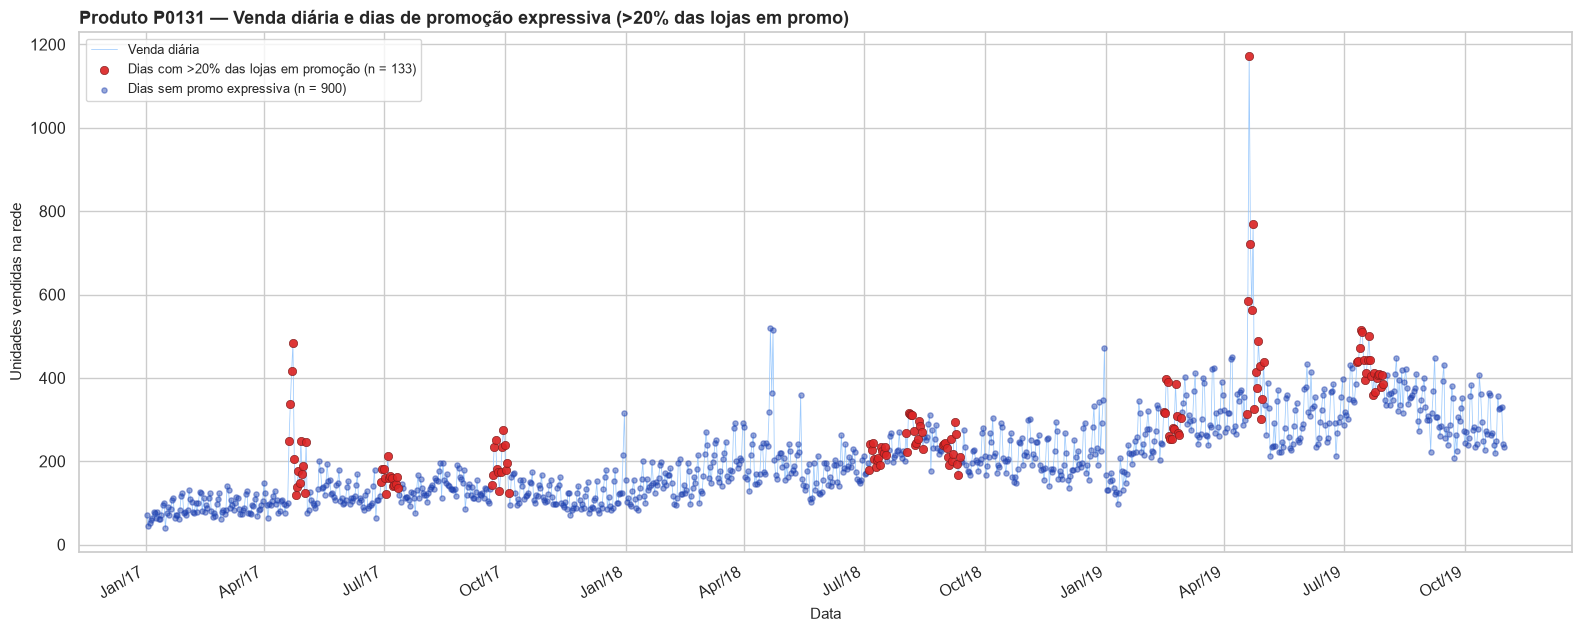

In [22]:
PRODUTO = "P0131"
LIMIAR_PROMO = 0.20  # 20% das lojas
LIMIAR_NAO_PROMO = 0.02  # 2% das lojas (quase nenhuma loja em promo)

df = pd.read_csv(CAMINHO_REDE, sep=",", parse_dates=["data"], dayfirst=False)
df_p = df[df["produto"] == PRODUTO].copy().sort_values("data").reset_index(drop=True)

print("DECISÃO REGISTRADA PARA FASE 3")
print("=" * 70)
print("Produtos que saem do painel (razão < 0,6):")
for p in ["P0438", "P0051", "P0079"]:
    print(f"  - {p}")
print("Filtro NÃO aplicado ainda — decisão somente aplicada na FASE 3.")
print()

print(f"PRODUTO {PRODUTO}")
print("=" * 70)

# --- Item 1: Plot venda diaria destacando dias com pct_lojas_promo > LIMIAR_PROMO ---
mask_promo = df_p["pct_lojas_promo"] > LIMIAR_PROMO
dias_promo = df_p.loc[mask_promo, "data"]
venda_promo = df_p.loc[mask_promo, "unidades"]
dias_não_promo = df_p.loc[~mask_promo, "data"]
venda_não_promo = df_p.loc[~mask_promo, "unidades"]

sns.set_theme(style="whitegrid", font_scale=1.05)
fig, ax = plt.subplots(figsize=(16, 6.5))

ax.plot(df_p["data"], df_p["unidades"].values, color="#93C5FD", linewidth=0.55,
        alpha=0.9, label="Venda diária", zorder=1)
ax.scatter(dias_promo, venda_promo.values, s=36, color="#DC2626", edgecolors="#7F1D1D",
           linewidths=0.5, alpha=0.92, zorder=3,
           label=f"Dias com >{int(LIMIAR_PROMO*100)}% das lojas em promoção (n = {mask_promo.sum()})")
ax.scatter(dias_não_promo, venda_não_promo.values, s=14, color="#1E40AF",
           alpha=0.45, zorder=2,
           label=f"Dias sem promo expressiva (n = {(~mask_promo).sum()})")

ax.set_title(f"Produto {PRODUTO} — Venda diária e dias de promoção expressiva"
               f" (>{int(LIMIAR_PROMO*100)}% das lojas em promo)",
               fontsize=13, fontweight="bold", loc="left")
ax.set_ylabel("Unidades vendidas na rede", fontsize=11)
ax.set_xlabel("Data", fontsize=11)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b/%y"))
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.legend(loc="upper left", frameon=True, fancybox=True, fontsize=9.5, ncol=1)

caminho_plot1 = os.path.join(PASTA_FIGURAS, f"venda_{PRODUTO}_destacando_promocao.png")
plt.tight_layout()
plt.savefig(caminho_plot1, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()


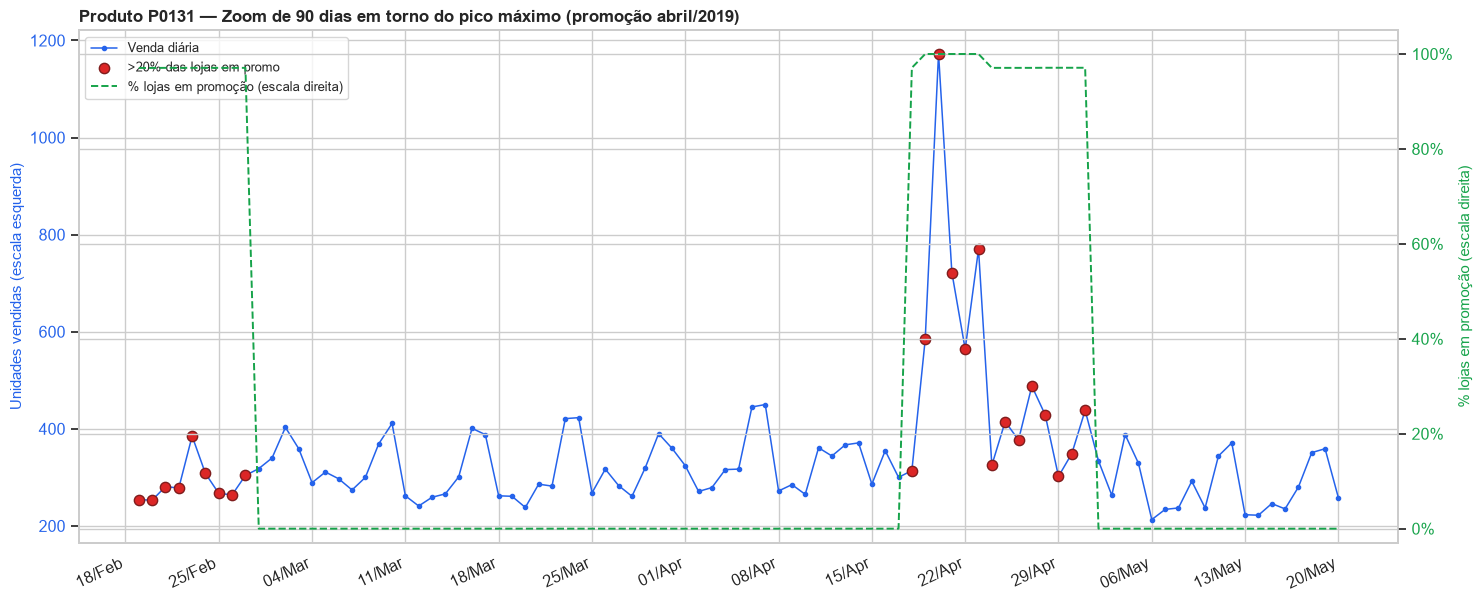

ITEM 1: Plots salvos:
  - Série completa destacando promoções: reports/figures\venda_P0131_destacando_promocao.png
  - Zoom de 90 dias no pico com % lojas em promo (eixo duplo): reports/figures\zoom_P0131_picopromocao_abril2019.png



In [23]:
# ZOOM 90 dias ao redor do grande pico (abril/2019) para melhor visualização
# do efeito promocional.
data_ref_pico = df_p.loc[df_p["unidades"].idxmax(), "data"]
inicio_zoom = data_ref_pico - pd.Timedelta(days=60)
fim_zoom = data_ref_pico + pd.Timedelta(days=30)

mask_zoom = (df_p["data"] >= inicio_zoom) & (df_p["data"] <= fim_zoom)
zoom = df_p[mask_zoom].copy()

fig, ax1 = plt.subplots(figsize=(15, 6.2))
mask_promo_z = zoom["pct_lojas_promo"] > LIMIAR_PROMO
ax1.plot(zoom["data"], zoom["unidades"], color="#2563EB", linewidth=1.1, marker="o", markersize=3,
          label="Venda diária")
ax1.scatter(zoom.loc[mask_promo_z, "data"], zoom.loc[mask_promo_z, "unidades"],
            s=55, color="#DC2626", edgecolors="#7F1D1D", zorder=5,
            label=f">20% das lojas em promo")
ax1.set_ylabel("Unidades vendidas (escala esquerda)", color="#2563EB", fontsize=10.5)
ax1.tick_params(axis="y", labelcolor="#2563EB")
ax1.set_title(f"Produto {PRODUTO} — Zoom de 90 dias em torno do pico máximo (promoção abril/2019)",
               fontsize=12, fontweight="bold", loc="left")
ax2 = ax1.twinx()
ax2.plot(zoom["data"], zoom["pct_lojas_promo"] * 100, color="#16A34A", linewidth=1.4, linestyle="--",
         label="% lojas em promoção (escala direita)")
ax2.set_ylabel("% lojas em promoção (escala direita)", color="#16A34A", fontsize=10.5)
ax2.tick_params(axis="y", labelcolor="#16A34A")
ax2.set_ylim(-3, 105)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

linhas1, rot1 = ax1.get_legend_handles_labels()
linhas2, rot2 = ax2.get_legend_handles_labels()
ax1.legend(linhas1 + linhas2, rot1 + rot2, loc="upper left", frameon=True, fancybox=True, fontsize=9.5)

ax1.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d/%b"))
plt.setp(ax1.get_xticklabels(), rotation=25, ha="right")

caminho_plot2 = os.path.join(PASTA_FIGURAS, f"zoom_{PRODUTO}_picopromocao_abril2019.png")
plt.tight_layout()
plt.savefig(caminho_plot2, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()

print(f"ITEM 1: Plots salvos:")
print(f"  - Série completa destacando promoções: {caminho_plot1}")
print(f"  - Zoom de 90 dias no pico com % lojas em promo (eixo duplo): {caminho_plot2}")
print()


In [24]:
# --- Item 2: Comparativo venda média (promo >20% vs promoção <= 2%
grupo_promo_forte = df_p[df_p["pct_lojas_promo"] > LIMIAR_PROMO]["unidades"]
grupo_sem_promo = df_p[df_p["pct_lojas_promo"] <= LIMIAR_NAO_PROMO]["unidades"]

media_promo_forte = grupo_promo_forte.mean()
media_sem_promo = grupo_sem_promo.mean()
razao_promo = media_promo_forte / media_sem_promo
mediana_promo = grupo_promo_forte.median()
mediana_sem_promo = grupo_sem_promo.median()
n_promo = len(grupo_promo_forte)
n_sem = len(grupo_sem_promo)
total_dias = len(df_p)
dias_intermediarios = total_dias - n_promo - n_sem

print(f"ITEM 2: Comparação de venda média: dias com >{int(LIMIAR_PROMO * 100)}% lojas em promoção")
print("       vs. dias com <={int(LIMIAR_NAO_PROMO * 100)}% lojas em promoção (quase sem promo)")
print("-" * 70)
print(f"  N dias com >{int(LIMIAR_PROMO*100)}% promo     : {n_promo:>4} de {total_dias} ({n_promo/total_dias*100:.2f}% dos dias)")
print(f"  N dias com <={int(LIMIAR_NAO_PROMO*100)}% promo    : {n_sem:>4} de {total_dias} ({n_sem/total_dias*100:.2f}% dos dias)")
print(f"  Dias intermediários (entre {int(LIMIAR_NAO_PROMO*100)}% e {int(LIMIAR_PROMO*100)}%) : {dias_intermediarios:>4} ({dias_intermediarios/total_dias*100:.2f}%)")
print()
print(f"  Média de venda (promo forte)     : {media_promo_forte:>8.2f} un/dia")
print(f"  Média de venda (sem promo)      : {media_sem_promo:>8.2f} un/dia")
print(f"  Razão (promo / sem promo)    : {razao_promo:>8.3f}x")
print(f"  Mediana (promo forte)        : {mediana_promo:>8.1f} un/dia")
print(f"  Mediana (sem promo)         : {mediana_sem_promo:>8.1f} un/dia")
print(f"  Razão mediana (promo/sem)      : {mediana_promo/mediana_sem_promo:>8.3f}x")
print()
print(f"  ⇒ A promoção multiplica a venda média diária em aproximadamente {razao_promo:.2f}x")
print(f"  (em mais de {int(LIMIAR_PROMO*100)}% das lojas) contra dias sem promoção.")
print()

# Distribuição por faixas de % de lojas em promoção (5 faixas)
print("  Bonus: Venda média por faixa de % lojas em promoção")
print("-" * 70)
faixas = [-0.001, 0.02, 0.20, 0.50, 0.80, 1.001]
rotulos_faixas = ["0–2%", "2%–20%", "20%–50%", "50%–80%", "80%–100%"]
df_p["faixa_promo"] = pd.cut(df_p["pct_lojas_promo"], bins=faixas, labels=rotulos_faixas, include_lowest=True)
tabela_faixas = df_p.groupby("faixa_promo", observed=False)["unidades"].agg([
    "count", "mean", "median", "min", "max"
]).round(2)
tabela_faixas.columns = ["n_dias", "media", "mediana", "min", "max"]
print(tabela_faixas.to_string())


ITEM 2: Comparação de venda média: dias com >20% lojas em promoção
       vs. dias com <={int(LIMIAR_NAO_PROMO * 100)}% lojas em promoção (quase sem promo)
----------------------------------------------------------------------
  N dias com >20% promo     :  133 de 1033 (12.88% dos dias)
  N dias com <=2% promo    :  900 de 1033 (87.12% dos dias)
  Dias intermediários (entre 2% e 20%) :    0 (0.00%)

  Média de venda (promo forte)     :   290.62 un/dia
  Média de venda (sem promo)      :   195.86 un/dia
  Razão (promo / sem promo)    :    1.484x
  Mediana (promo forte)        :    252.0 un/dia
  Mediana (sem promo)         :    177.0 un/dia
  Razão mediana (promo/sem)      :    1.424x

  ⇒ A promoção multiplica a venda média diária em aproximadamente 1.48x
  (em mais de 20% das lojas) contra dias sem promoção.

  Bonus: Venda média por faixa de % lojas em promoção
----------------------------------------------------------------------
             n_dias   media  mediana    min     max
f

## 2.9 Conclusões da Fase 2

- A coluna **`unidades` é venda** (truncada por ruptura), não demanda latente; **`estoque_total` é saldo de
  fim de dia**. Isso orienta a modelagem (não tratar a venda como demanda pura) e a simulação de custo.
- O grão escolhido é **produto × dia na rede**: a série agregada é muito mais regular que a série de loja,
  e a decisão de compra é centralizada no CD.
- Há **sazonalidade semanal** clara (período 7) no P0131, confirmada pela STL (força da sazonalidade ≈ 0,41;
  força da tendência ≈ 0,86), justificando modelos com componente sazonal.
- A **promoção** multiplica a venda (~1,48×) e é **conhecida com antecedência** → será usada como variável
  exógena futura conhecida.
- A **triagem dos 30 produtos** identificou 3 itens com razão recente/anterior < 0,6 (P0438, P0051, P0079):
  a remoção efetiva ocorre na **Fase 3**.
